# 13 — La vigilancia completa: la salud de toda la ciudad

## Qué contesta este cuaderno

El SIVIGILA es la fuente más abundante del proyecto y la menos usada: se integraron 14 eventos y se miraron 2 o 3. El propietario pide mirar **la salud de toda la ciudad como variable general**, no casos puntuales, y le preocupa el **sobreajuste** (`docs/CONTEXTO.md`, 2026-09-30, «Cambio de enfoque»). Este cuaderno hace, sobre la vigilancia, lo preregistrado en `patrones/datos/variables.csv` (filas `barrido_vigilancia` e `indices_generales`):

1. **Inventario** de todas las series semanales, con su cobertura y sus escalones.
2. **Barrido** de cada serie de Manizales y Caldas, en anomalía, rezagos 0-8, contra el desenlace común. Benjamini-Hochberg sobre la familia entera.
3. **Confirmación** en 2025 de lo que sobrevive. Solo cuenta lo confirmado.
4. **Índice de «presión epidemiológica»**: componentes principales ajustados solo en descubrir.
5. **¿Caldas o Colombia se adelantan a Manizales?**
6. **Rezago de publicación**: qué se puede calcular a tiempo para pronosticar.
7. **Qué entra al repertorio.**

## El desenlace

`from desenlace import desenlace_semanal`, columna `y`: triage total por semana epidemiológica, en log, **sin calendario y sin los cortes de nivel de la red** (Nueva EPS), **con la estacionalidad**. Descubrir: 2022-03 a 2024-12. Confirmar: **2025-01 a 2025-12**, porque los microdatos del SIVIGILA terminan en 2025. Desenlaces secundarios: `y_respiratorio`, `y_infecciosas` y `y_trauma`, de los diagnósticos del cuaderno 10.

Todo sale de archivos del repositorio. No hay conexión a la base del hospital.

In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
DIVERGE = LinearSegmentedColormap.from_list("diverge", [AZUL, "#f4f3f0", ROJO])
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SES = 170010010301
COVID = ("2020-03-01", "2021-12-31")
DESC = ("2022-03-06", "2024-12-29")          # descubrir (desenlace.py)
CONF = ("2025-01-05", "2025-12-28")          # confirmar: el SIVIGILA termina en 2025
REZ = list(range(0, 9))
q_BH = 0.10
rejilla = pd.date_range("2015-01-04", "2025-12-28", freq="W-SUN")

vig = pd.concat([pd.read_csv(RAIZ / f"calendarios/{n}.csv.gz") for n in ("vigilancia_sivigila", "vigilancia_sivigila_eventos")],
                ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
PV = vig.pivot_table(index="fecha_inicio_semana", columns=["ambito", "evento", "variable"], values="valor", aggfunc="sum")
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
# Error de la fuente (sección 1): la SE53 de 2025 del 998 multiplica por ~7 la EDA de Manizales en todas las bandas a la vez
SE53 = pd.Timestamp("2025-12-28")
cols998 = [c for c in PV.columns if c[1] == 998 and c[0] in ("manizales", "caldas") and c[2].startswith("casos_eda")]
print("998, SE53 de 2025 antes de anular:", {f"{c[0]} {c[2]}": PV.loc[SE53, c] for c in cols998 if c[2] == "casos_eda_total"})
PV.loc[SE53, cols998] = np.nan
def serie(ambito, evento, variable):
    col = (ambito, evento, variable)
    return PV[col].reindex(rejilla) if col in PV.columns else None

Y = desenlace_semanal()
print("vigilancia:", PV.index.min().date(), "a", PV.index.max().date(), "|", PV.shape[1], "columnas")
print("desenlace:", Y.index.min().date(), "a", Y.index.max().date(), "| columnas:", [c for c in Y.columns if c.startswith("y")])

998, SE53 de 2025 antes de anular: {'caldas casos_eda_total': 2640.0, 'manizales casos_eda_total': 2495.0}
vigilancia: 2011-01-02 a 2025-12-28 | 464 columnas
desenlace: 2022-03-06 a 2026-09-13 | columnas: ['y', 'y_respiratorio', 'y_infecciosas', 'y_trauma']


---
# 1. Inventario: qué series de vigilancia hay

Tres niveles geográficos (Manizales, Caldas, Colombia) y tres fuentes:
- **995, IRA colectiva**: consultas por IRA por edad, hospitalización por IRAG, UCI y muertes. Una fila por institución y semana, con denominador.
- **998, EDA colectiva**: casos por banda de edad y hospitalizados. Sin denominador.
- **Eventos individuales**: 14 integrados, más 3 marcadores (pólvora, brotes de ETA, IRAG inusitado).

Y una cuarta, construida aquí: la **IRA de Manizales sin el SES** (institución `170010010301`), desde el archivo por institución, porque el SES es el propio hospital.

**Conteos, no proporciones.** El denominador del 995 crece por escalones (+60 % en 2021, +35 % en 2024; `VIGILANCIA.md`): la proporción IRA no es comparable entre años. Se usa el conteo, y el nivel de cada año se quita en la anomalía.

In [2]:
BANDAS_IRA = ["0_4", "5_19", "20_39", "40_59", "60_mas"]
BANDAS_EDA = ["0_4", "5_14", "15_44", "45_64", "65_mas"]
FUGA = {300, 356, 365, 370, 549, 875}         # personas que pueden ser las mismas que llegan al triage
NOMBRE_EV = {300: "agresiones por animales", 875: "violencias de género e intrafamiliar", 356: "intento de suicidio",
             365: "intoxicaciones (365)", 370: "intoxicación por fármacos", 549: "morbilidad materna extrema",
             831: "varicela", 155: "cáncer de mama y cuello", 850: "VIH / sida", 813: "tuberculosis (813)",
             820: "tuberculosis pulmonar", 113: "desnutrición aguda < 5", 620: "parotiditis"}
FAMILIA_EV = {300: "lesiones", 875: "violencia", 356: "salud mental", 365: "intoxicaciones", 370: "intoxicaciones",
              549: "materno", 831: "contagio", 155: "crónico", 850: "crónico", 813: "crónico", 820: "crónico",
              113: "nutrición", 620: "contagio"}
catalogo = []
for amb in ["manizales", "caldas", "colombia"]:
    var_ev = "casos_total" if amb == "colombia" else "casos_ocurrencia"
    catalogo += [(amb, "IRA total", 995, "consultas_ira_total", "respiratorio")]
    catalogo += [(amb, f"IRA {b.replace('_', '-').replace('-mas', '+')}", 995, f"consultas_ira_{b}", "respiratorio") for b in BANDAS_IRA]
    catalogo += [(amb, "IRAG hospitalización", 995, "hospitalizaciones_irag_total", "respiratorio grave"),
                 (amb, "IRAG UCI", 995, "uci_irag_total", "respiratorio grave"),
                 (amb, "IRAG muertes", 995, "muertes_irag_total", "respiratorio grave")]
    catalogo += [(amb, "EDA total", 998, "casos_eda_total", "gastro")]
    catalogo += [(amb, f"EDA {b.replace('_', '-').replace('-mas', '+')}", 998, f"casos_eda_{b}", "gastro") for b in BANDAS_EDA]
    catalogo += [(amb, "EDA hospitalizados", 998, "casos_eda_hospitalizados", "gastro")]
    catalogo += [(amb, NOMBRE_EV[e], e, var_ev, FAMILIA_EV[e]) for e in NOMBRE_EV]
S = {}                                      # (ambito, nombre) -> serie semanal de conteos
meta = {}
for amb, nom, ev, var, fam in catalogo:
    s = serie(amb, ev, var)
    if s is not None:
        S[(amb, nom)] = s; meta[(amb, nom)] = {"fuente": ev, "familia": fam}
ira_sin_ses = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum().reindex(rejilla)
S[("manizales", "IRA total sin SES")] = ira_sin_ses; meta[("manizales", "IRA total sin SES")] = {"fuente": 995, "familia": "respiratorio"}
ses_anual = inst[inst.cod_upgd.eq(SES)].groupby(inst.fecha_inicio_semana.dt.year)["consultas_ira"].sum()
tot_anual = inst.groupby(inst.fecha_inicio_semana.dt.year)["consultas_ira"].sum()
print("IRA notificada por el SES al 995, % de la IRA de Manizales:",
      (100 * ses_anual.reindex(tot_anual.index).fillna(0) / tot_anual).loc[2015:].round(2).to_dict())
print("r semanal IRA total vs IRA sin SES, 2015-2025:", round(S[("manizales", "IRA total")].corr(ira_sin_ses), 4))

# Semanas imposibles: más de 3 veces, o menos de un tercio, de la mediana de las 9 semanas vecinas (series con mediana >= 20)
marcas = []
for (amb, nom), s in S.items():
    s = s.loc["2015":]
    if amb == "colombia" or s.median() < 20: continue
    med = s.rolling(9, center=True, min_periods=5).median(); r = s / med
    marcas += [{"ámbito": amb, "serie": nom, "semana": str(f.date()), "valor": int(s[f]), "mediana vecina": int(med[f])}
               for f in r[(r > 3) | (r < 1 / 3)].index]
marcas = pd.DataFrame(marcas)
print(f"Semanas marcadas (Manizales y Caldas, 2015-2025, ya sin la SE53 del 998): {len(marcas)}; "
      f"en 2022-2025: {int((marcas.semana >= '2022').sum())}")
display(marcas[marcas.semana >= "2022"])

filas = []
for (amb, nom), s in S.items():
    x = s.dropna(); x = x[x.index >= "2015-01-01"]
    d, c = s.loc[DESC[0]:DESC[1]], s.loc[CONF[0]:CONF[1]]
    filas.append({"ámbito": amb, "serie": nom, "fuente": meta[(amb, nom)]["fuente"], "familia": meta[(amb, nom)]["familia"],
                  "desde": x.index.min().year if len(x) else None,
                  "media/sem 2022-24": round(d.mean(), 1), "media/sem 2025": round(c.mean(), 1),
                  "% semanas en 0 (2022-25)": round(100 * (pd.concat([d, c]) == 0).mean()),
                  "fuga posible": "sí" if meta[(amb, nom)]["fuente"] in FUGA else ""})
INV = pd.DataFrame(filas)
print("Parte de Manizales dentro de Caldas, conteos 2022-2025 (%):",
      {n: round(100 * S[("manizales", n)].loc["2022":].sum() / S[("caldas", n)].loc["2022":].sum()) for n in ["IRA total", "EDA total", "EDA hospitalizados"]})
print(f"{len(INV)} series: {INV.ámbito.value_counts().to_dict()}")
INV[INV.ámbito.eq("manizales")].set_index("serie").drop(columns="ámbito")

IRA notificada por el SES al 995, % de la IRA de Manizales: {2015: 0.22, 2016: 0.06, 2017: 0.0, 2018: 0.0, 2019: 0.0, 2020: 0.06, 2021: 0.07, 2022: 0.0, 2023: 0.05, 2024: 0.17, 2025: 0.0}
r semanal IRA total vs IRA sin SES, 2015-2025: 1.0
Semanas marcadas (Manizales y Caldas, 2015-2025, ya sin la SE53 del 998): 39; en 2022-2025: 9


,ámbito,serie,semana,valor,mediana vecina
9,manizales,EDA 5-14,2022-06-26,7,23
29,caldas,EDA hospitalizados,2023-04-02,75,22
30,caldas,EDA hospitalizados,2023-05-07,84,27
31,caldas,EDA hospitalizados,2023-12-24,10,42
32,caldas,EDA hospitalizados,2024-04-14,148,37
33,caldas,EDA hospitalizados,2024-04-21,237,37
34,caldas,EDA hospitalizados,2024-04-28,254,37
35,caldas,EDA hospitalizados,2024-10-13,9,28
36,caldas,EDA hospitalizados,2025-05-25,198,41


Parte de Manizales dentro de Caldas, conteos 2022-2025 (%): {'IRA total': 68, 'EDA total': 65, 'EDA hospitalizados': 70}
88 series: {'manizales': 30, 'caldas': 29, 'colombia': 29}


,fuente,familia,desde,media/sem 2022-24,media/sem 2025,% semanas en 0 (2022-25),fuga posible
serie,,,,,,,
IRA total,995,respiratorio,2015,1180.9,1274.9,0,
IRA 0-4,995,respiratorio,2015,167.6,143.9,0,
IRA 5-19,995,respiratorio,2015,184.6,171.3,0,
IRA 20-39,995,respiratorio,2015,370.1,376.6,0,
IRA 40-59,995,respiratorio,2015,231.9,279.2,0,
IRA 60+,995,respiratorio,2015,226.8,303.9,0,
IRAG hospitalización,995,respiratorio grave,2015,39.3,37.5,0,
IRAG UCI,995,respiratorio grave,2015,13.8,19.8,0,
IRAG muertes,995,respiratorio grave,2015,4.8,1.9,10,


## Lectura

**88 series semanales**: 30 de Manizales, 29 de Caldas y 29 de Colombia. Por fuente: 9 del 995 (IRA total, 5 bandas de edad, hospitalización, UCI y muertes por IRAG), 7 del 998 (EDA total, 5 bandas, hospitalizados) y 13 eventos individuales. En Manizales, además, la IRA sin el SES.

- **Quitar el SES no cambia nada.** El SES notifica al 995 entre el **0 % y el 0,22 %** de la IRA de Manizales desde 2015 (0 % en 2025), y la IRA con y sin él correlaciona **1,0** semana a semana. El hospital casi no notifica su IRA a la vigilancia colectiva, así que la IRA de la ciudad **no contiene mecánicamente** al hospital. Se deja la serie en el barrido por transparencia, pero es la misma.
- **Volumen.** IRA ~1.181 consultas por semana en 2022-2024 (1.275 en 2025); EDA ~398 casos (365 en 2025). Entre los eventos, agresiones por animales (~25) y violencias (~24) son los grandes; desnutrición aguda (32 % de semanas en cero) y parotiditis (40 %) son casi vacías.
- **Error de la fuente, anulado:** la **SE53 de 2025 del 998** trae 2.495 casos de EDA en Manizales y 2.640 en Caldas, unas 7 veces una semana normal, con todas las bandas de edad a la vez y sin reflejo en Colombia. Se trata como hueco. Hay que corregirlo también en `calendarios/vigilancia/sivigila.py`: aquí solo se anula en memoria.
- **Otras semanas raras** (más de 3 veces o menos de un tercio de sus 9 vecinas): 9 en 2022-2025, casi todas en la **EDA hospitalizada de Caldas**, que tiene brotes de 148-254 hospitalizados por semana en abril de 2024 (contra 37 de mediana). Como la de Manizales ronda 26, esos brotes son de otros municipios. Se dejan: pueden ser reales.
- **Fuera del barrido:** la COVID (346), que solo existe desde 2024 y no deja estimar una estación; y los tres marcadores (pólvora, brotes de ETA, IRAG inusitado), que son semanas sueltas, no series. El 348 además absorbió COVID en 2022-2023.
- **Seis series pueden ser las mismas personas del triage** (columna «fuga posible»): agresiones por animales, violencias, intento de suicidio, intoxicaciones (365 y 370) y morbilidad materna extrema.

**Límite.** Colombia solo entra en la sección 5; el barrido es Manizales y Caldas, como se preregistró. Caldas **incluye** a Manizales.

## Los escalones, en conteos

Conteo anual de cada serie de Manizales dividido por su media de 2015-2019. Así se comparan años sin pasar por la proporción, que arrastra el escalón del denominador. Se añade el número de instituciones que notifican el 995 y el 998, que es la **cobertura**.

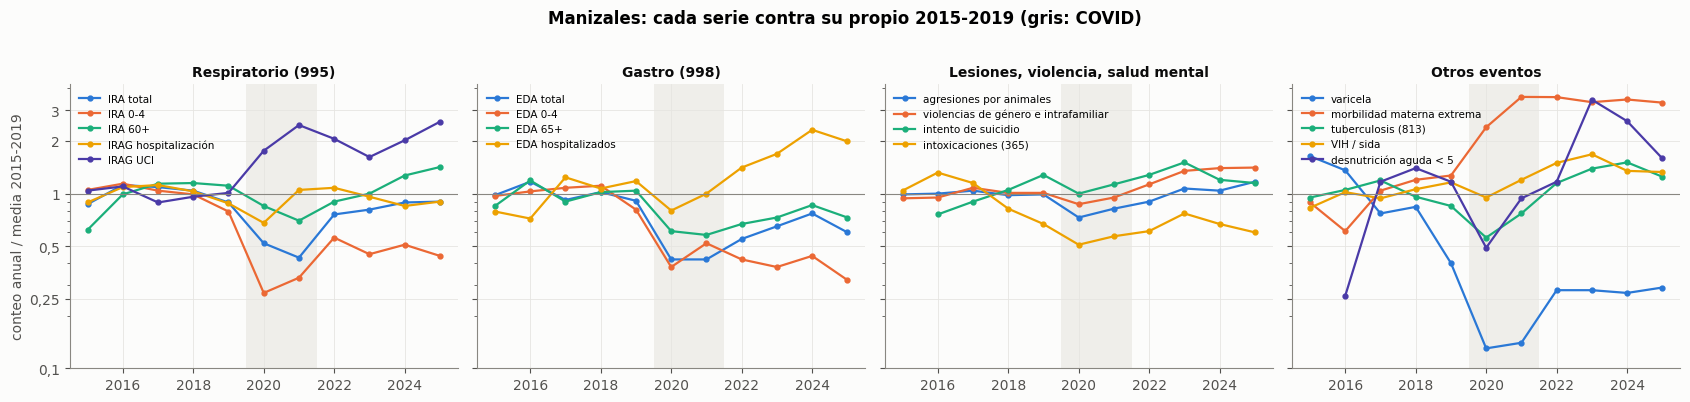

,instituciones 995,instituciones 998,IRA total,IRA 0-4,IRAG hospitalización,IRAG UCI,EDA total,EDA hospitalizados,intento de suicidio,violencias de género e intrafamiliar,intoxicaciones (365),morbilidad materna extrema,varicela,desnutrición aguda < 5
2015,37.2,33.6,0.87,1.05,0.89,1.04,0.98,0.79,NaN,0.94,1.04,0.89,1.64,NaN
2016,55.9,33.4,1.12,1.14,1.09,1.10,1.17,0.72,0.76,0.95,1.32,0.61,1.36,0.26
2017,50.2,32.1,1.09,1.04,1.12,0.89,0.92,1.24,0.90,1.08,1.15,1.04,0.77,1.17
2018,48.5,29.5,1.04,0.99,1.03,0.96,1.02,1.07,1.05,1.01,0.82,1.20,0.84,1.40
2019,44.2,26.8,0.89,0.79,0.88,1.01,0.91,1.18,1.28,1.01,0.67,1.27,0.40,1.17
2020,34.2,21.1,0.52,0.27,0.68,1.76,0.42,0.80,1.00,0.87,0.51,2.40,0.13,0.49
2021,36.8,22.1,0.43,0.33,1.05,2.47,0.42,1.00,1.13,0.95,0.57,3.58,0.14,0.94
2022,38.3,21.0,0.76,0.56,1.08,2.06,0.55,1.41,1.28,1.13,0.61,3.57,0.28,1.17
2023,40.5,21.0,0.81,0.45,0.96,1.62,0.65,1.69,1.51,1.35,0.77,3.34,0.28,3.45
2024,50.3,26.0,0.89,0.51,0.85,2.02,0.77,2.32,1.20,1.40,0.67,3.46,0.27,2.60


In [3]:
anual = pd.DataFrame({nom: s.groupby(s.index.year).sum(min_count=40) for (amb, nom), s in S.items() if amb == "manizales"}).loc[2015:2025]
cobertura = pd.DataFrame({f"instituciones {e}": serie("manizales", e, "n_instituciones_notificando").groupby(rejilla.year).mean()
                          for e in (995, 998)}).loc[2015:2025].round(1)
indice = (anual / anual.loc[2015:2019].mean()).round(2)
grupos_fig = [("Respiratorio (995)", ["IRA total", "IRA 0-4", "IRA 60+", "IRAG hospitalización", "IRAG UCI"]),
              ("Gastro (998)", ["EDA total", "EDA 0-4", "EDA 65+", "EDA hospitalizados"]),
              ("Lesiones, violencia, salud mental", ["agresiones por animales", "violencias de género e intrafamiliar", "intento de suicidio", "intoxicaciones (365)"]),
              ("Otros eventos", ["varicela", "morbilidad materna extrema", "tuberculosis (813)", "VIH / sida", "desnutrición aguda < 5"])]
colores = [AZUL, NARANJA, AQUA, AMARILLO, VIOLETA]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, (tit, cols) in zip(axes, grupos_fig):
    for c, col in zip(cols, colores):
        ax.plot(indice.index, indice[c], marker="o", ms=3.5, lw=1.6, color=col, label=c)
    ax.axhline(1, color=MUDO, lw=.8); ax.axvspan(2019.5, 2021.5, color="#efeeea", lw=0)
    ax.set_title(tit, fontsize=10); ax.legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("conteo anual / media 2015-2019"); axes[0].set_yscale("log")
axes[0].set_yticks([0.1, 0.25, 0.5, 1, 2, 3]); axes[0].set_yticklabels(["0,1", "0,25", "0,5", "1", "2", "3"])
plt.suptitle("Manizales: cada serie contra su propio 2015-2019 (gris: COVID)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
pd.concat([cobertura, indice[["IRA total", "IRA 0-4", "IRAG hospitalización", "IRAG UCI", "EDA total", "EDA hospitalizados", "intento de suicidio",
                              "violencias de género e intrafamiliar", "intoxicaciones (365)", "morbilidad materna extrema",
                              "varicela", "desnutrición aguda < 5"]]], axis=1)

## Lectura

**Casi todas las series tienen escalones, y varios no son epidemiología.** Conteo anual sobre la media de 2015-2019:

| Serie | 2019 | 2022 | 2024 | 2025 | Qué es |
|---|---|---|---|---|---|
| Instituciones que notifican el 995 | 44,2 | 38,3 | 50,3 | 53,6 | **Cobertura**: sube un tercio entre 2022 y 2025 |
| Instituciones que notifican el 998 | 26,8 | 21,0 | 26,0 | 27,8 | Cae en la pandemia y no vuelve a 2015-2017 (33) |
| IRA total | 0,89 | 0,76 | 0,89 | 0,90 | No vuelve al nivel prepandemia |
| IRA 0-4 | 0,79 | 0,56 | 0,51 | **0,44** | La IRA infantil está a menos de la mitad |
| IRAG UCI | 1,01 | 2,06 | 2,02 | **2,58** | Más que duplicada desde 2020 |
| EDA total | 0,91 | 0,55 | 0,77 | 0,60 | Caída desde 2020, sin resolver (`VIGILANCIA.md`) |
| **EDA hospitalizados** | 1,18 | 1,41 | **2,32** | 1,99 | **Sube mientras la EDA total baja**: más hospitalización por caso o cambio de registro [I] |
| Morbilidad materna extrema | 1,27 | 3,57 | 3,46 | 3,32 | Escalón ×3 en 2020-2021, de definición |
| Varicela | 0,40 | 0,28 | 0,27 | 0,29 | Caída por vacunación y pandemia |
| Violencias | 1,01 | 1,13 | 1,40 | 1,41 | Sube +40 % |

Consecuencias:
- **Ninguna proporción ni ningún nivel se compara entre años.** Por eso el barrido usa la anomalía con el nivel de cada año quitado.
- Los escalones **dentro** del año no los quita la media anual. El de EDA hospitalizados (2022 → 2024) es el que más preocupa, y vuelve a aparecer en la sección 4b.
- La IRA infantil de la ciudad está hoy a menos de la mitad de 2015-2019. Cualquier «temporada respiratoria» actual es más baja que las de antes de la pandemia.

## Cómo se construye la anomalía

Para cada serie: `log(1 + conteo)`, menos la **forma estacional típica** (3 armónicos anuales, ajustados en 2015-2019 y 2022-2024, **nunca con 2025**), menos la **media de cada año**. Lo que queda es «esta semana hubo más o menos de lo normal para esta época y este año». Así ni el escalón de cobertura ni la estación típica cuentan como señal.

Límite que hay que tener presente: la media del año se calcula con el año entero. Para operar habría que cambiarla por una media móvil hacia atrás (se vuelve en la sección 6).

Amplitud de la forma estacional típica (pico/valle - 1, %), Manizales:
{'IRA total': 30, 'IRA 0-4': 63, 'IRAG hospitalización': 62, 'EDA total': 52, 'intento de suicidio': 43, 'varicela': 58}


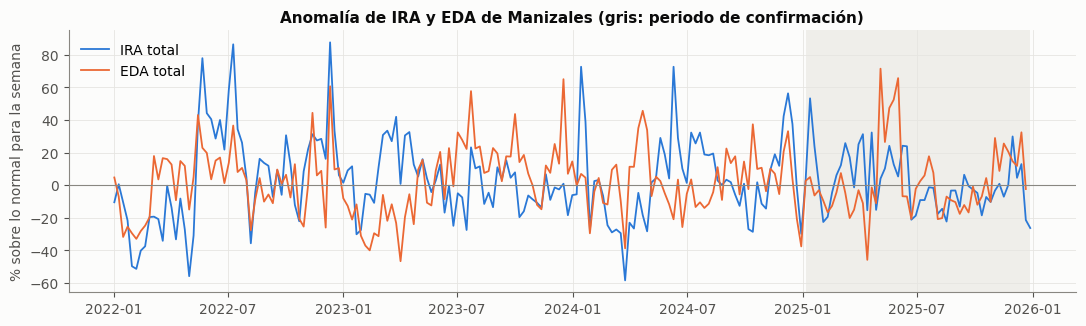

In [4]:
t_ano = rejilla.dayofyear.values / 365.25
FOURIER = pd.DataFrame({f"{n}{k}": f(2 * np.pi * k * t_ano) for k in (1, 2, 3) for n, f in (("s", np.sin), ("c", np.cos))}, index=rejilla)
FOURIER.insert(0, "c", 1.0)
en_ajuste = (~rejilla.to_series().between(*COVID)).values & (rejilla <= "2024-12-31")
def anomalia(s, devolver_estacion=False):
    l = np.log1p(s.astype(float).reindex(rejilla))
    lc = l - l.groupby(l.index.year).transform("mean")
    ok = lc.notna().values & en_ajuste
    b, *_ = np.linalg.lstsq(FOURIER.values[ok], lc.values[ok], rcond=None)
    est = pd.Series(FOURIER.values @ b, index=rejilla)
    r = l - est
    r = r - r.groupby(r.index.year).transform("mean")
    return (r, est) if devolver_estacion else r
A = {k: anomalia(s) for k, s in S.items()}
amplitud = {k[1]: round(100 * (np.exp(anomalia(s, True)[1].max() - anomalia(s, True)[1].min()) - 1)) for k, s in S.items() if k[0] == "manizales"}
print("Amplitud de la forma estacional típica (pico/valle - 1, %), Manizales:")
print({k: amplitud[k] for k in ["IRA total", "IRA 0-4", "IRAG hospitalización", "EDA total", "intento de suicidio", "varicela"]})
fig, ax = plt.subplots(figsize=(13, 3.4))
for (k, col) in [(("manizales", "IRA total"), AZUL), (("manizales", "EDA total"), NARANJA)]:
    a = A[k].loc["2022":"2025"]
    ax.plot(a.index, 100 * (np.exp(a) - 1), color=col, lw=1.3, label=k[1])
ax.axhline(0, color=MUDO, lw=.8); ax.axvspan(pd.Timestamp(CONF[0]), pd.Timestamp(CONF[1]), color="#efeeea", lw=0)
ax.set_ylabel("% sobre lo normal para la semana"); ax.legend()
ax.set_title("Anomalía de IRA y EDA de Manizales (gris: periodo de confirmación)"); plt.show()

## Lectura

La forma estacional típica es grande: de valle a pico, **+30 %** en la IRA total, **+63 %** en la IRA 0-4, **+62 %** en la hospitalización por IRAG, **+52 %** en la EDA, **+43 %** en el intento de suicidio y **+58 %** en la varicela. Todo eso sale de la anomalía: lo que queda es cuánto se aparta cada semana de lo normal para esa época y ese año.

En la figura, 2022 es el año más movido de la IRA (semanas por encima de +50 % y cerca de −50 % de lo normal), y desde 2023 las dos series oscilan en una banda más estrecha.

**Límite.** Tres armónicos son una forma suave. Si la estación de los años recientes es distinta de la de 2015-2024, parte de esa diferencia se queda en la anomalía. Esto resulta importante en la sección 4b.

---
# 2. Barrido: cada serie de Manizales y Caldas contra el desenlace

Lo preregistrado (`barrido_vigilancia` en `variables.csv`): cada serie en anomalía, con rezagos de 0 a 8 semanas, contra `y` (triage total semanal, log, sin calendario y sin los cortes de la red, **con** estacionalidad), en **descubrir** (2022-03 a 2024-12).

- Una regresión por serie y rezago: `y_t = a + b · x_{t−k}`, con `x` en desviaciones típicas (de descubrir) y **errores HAC** (Newey-West, 4 rezagos), porque las dos series tienen autocorrelación.
- `100·b` ≈ % de triage por desviación típica de la serie.
- **Benjamini-Hochberg, q = 0,10, sobre toda la familia**: las dos geografías, todas las series y los 9 rezagos, incluido el 0.

**Aviso de fuga.** Intento de suicidio, violencias, intoxicaciones, agresiones por animales y morbilidad materna son **personas** que pueden ser las mismas que llegan al triage: con rezago 0 son parte del desenlace. Además, el rezago 0 de cualquier serie no está disponible a tiempo para pronosticar. Por las dos razones, **el rezago 0 entra en la familia de BH (la hace más exigente) pero no cuenta como hallazgo.** Solo cuentan los rezagos ≥ 1.

**Criterio de confirmación, fijado antes de mirar 2025:** mismo rezago, mismo signo y p unilateral HAC < 0,05 en 2025-01 a 2025-12 (52 semanas). Todo lo demás es «no confirmado».

In [5]:
SD_DESC = {}
def ajuste(y, x, k, periodo, sd=None):
    d = pd.DataFrame({"y": y, "x": x.shift(k)}).loc[periodo[0]:periodo[1]].dropna()
    xs = d.x / (sd if sd else d.x.std())
    m = sm.OLS(d.y, sm.add_constant(xs)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    return m.params.iloc[1], m.bse.iloc[1], m.pvalues.iloc[1], len(d), d.x.std()
yv = Y["y"].reindex(pd.date_range(rejilla[0], Y.index.max(), freq="W-SUN"))
def sin_estacion(y):
    """El desenlace sin su propia forma estacional (3 armónicos ajustados solo en descubrir). Se usa en la sección 4b."""
    t = y.index.dayofyear.values / 365.25
    F = np.column_stack([np.ones(len(y))] + [f(2 * np.pi * k * t) for k in (1, 2, 3) for f in (np.sin, np.cos)])
    ok = (y.notna() & (y.index >= DESC[0]) & (y.index <= DESC[1])).values
    b, *_ = np.linalg.lstsq(F[ok], y.values[ok], rcond=None)
    return y - F @ b
yv_des = sin_estacion(yv)
filas = []
for (amb, nom), a in A.items():
    if amb == "colombia": continue
    a = a.reindex(yv.index)
    for k in REZ:
        b, se, p, n, sd = ajuste(yv, a, k, DESC)
        filas.append({"ámbito": amb, "serie": nom, "fuente": meta[(amb, nom)]["fuente"], "familia": meta[(amb, nom)]["familia"],
                      "rezago": k, "efecto %": 100 * b, "ee": 100 * se, "p": p, "n": n, "sd_desc": sd})
B = pd.DataFrame(filas)
B["q"] = multipletests(B.p, method="fdr_bh")[1]
B["sobrevive BH"] = B.q < q_BH
B["cuenta"] = B["sobrevive BH"] & B.rezago.ge(1)
print(f"Desviación típica del desenlace y en descubrir: {100 * yv.loc[DESC[0]:DESC[1]].std():.1f} % (log)")
print(f"Pruebas: {len(B)} = {B.groupby('ámbito').serie.nunique().to_dict()} series x {len(REZ)} rezagos")
print(f"Sobreviven a BH (q < {q_BH}): {B['sobrevive BH'].sum()} | de ellas con rezago >= 1: {B.cuenta.sum()} "
      f"| series distintas con rezago >= 1: {B[B.cuenta].groupby(['ámbito', 'serie']).ngroups}")
print(f"p < 0,05 sin corregir: {(B.p < .05).sum()} de {len(B)} (por azar se esperarían {0.05 * len(B):.0f})")

Desviación típica del desenlace y en descubrir: 6.1 % (log)
Pruebas: 531 = {'caldas': 29, 'manizales': 30} series x 9 rezagos
Sobreviven a BH (q < 0.1): 13 | de ellas con rezago >= 1: 10 | series distintas con rezago >= 1: 5
p < 0,05 sin corregir: 63 de 531 (por azar se esperarían 27)


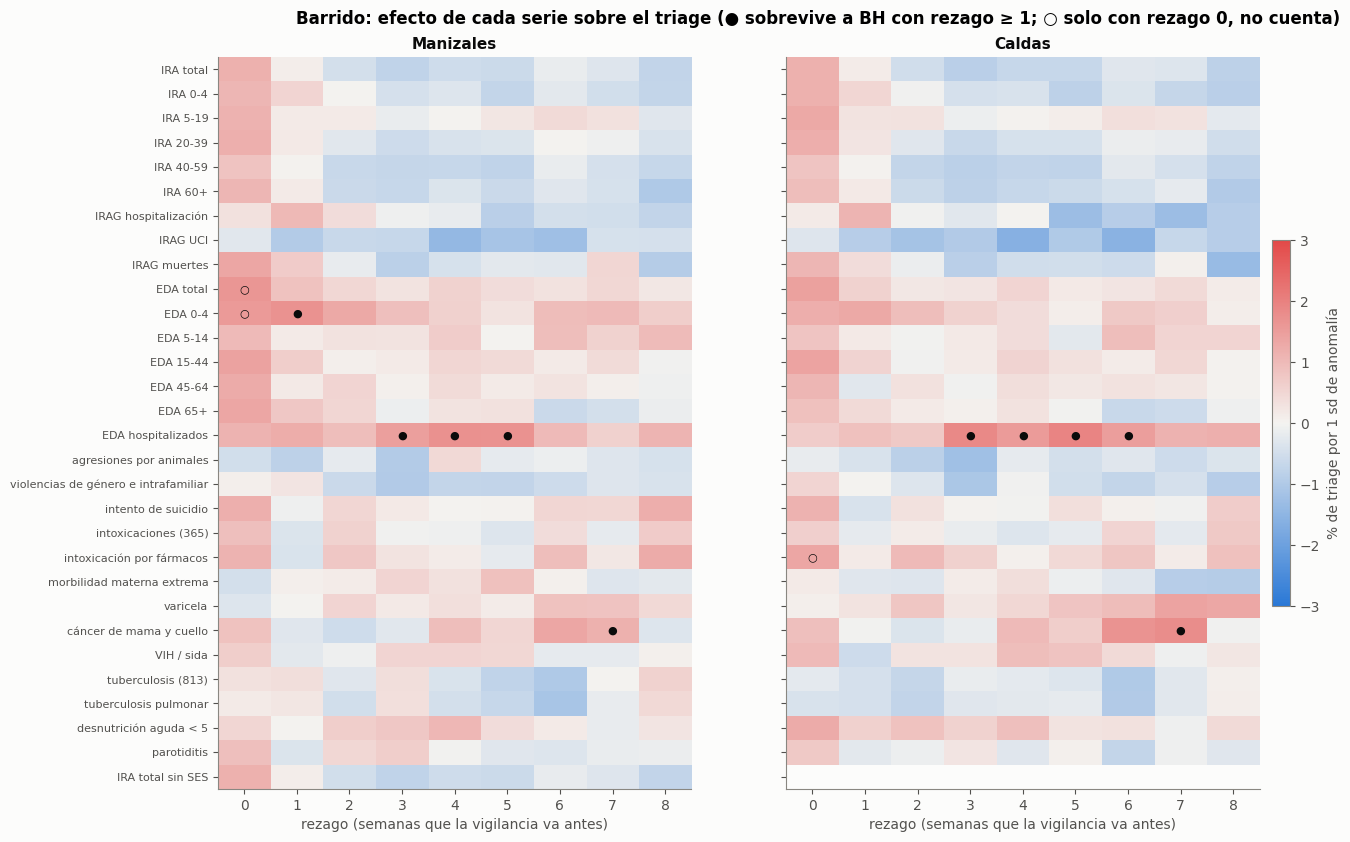

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9.5), sharey=True)
orden = [n for (a, n) in A if a == "manizales"]
for ax, amb in zip(axes, ["manizales", "caldas"]):
    M = B[B.ámbito.eq(amb)].pivot(index="serie", columns="rezago", values="efecto %").reindex(orden)
    Q = B[B.ámbito.eq(amb)].pivot(index="serie", columns="rezago", values="sobrevive BH").reindex(orden)
    im = ax.imshow(M.values, cmap=DIVERGE, vmin=-3, vmax=3, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if Q.values[i, j] == True:
                ax.text(j, i, "●" if j >= 1 else "○", ha="center", va="center", fontsize=8, color=TINTA)
    ax.set_xticks(range(len(REZ)), REZ); ax.set_yticks(range(len(orden)), orden, fontsize=8)
    ax.set_xlabel("rezago (semanas que la vigilancia va antes)"); ax.set_title(amb.capitalize()); ax.grid(False)
cb = fig.colorbar(im, ax=axes, shrink=.5, pad=.01); cb.set_label("% de triage por 1 sd de anomalía")
plt.suptitle("Barrido: efecto de cada serie sobre el triage (● sobrevive a BH con rezago ≥ 1; ○ solo con rezago 0, no cuenta)",
             fontweight="bold", y=.93)
plt.show()

In [7]:
SOB = B[B.cuenta].copy()
def confirmar(r):
    x = A[(r.ámbito, r.serie)].reindex(yv.index)
    b, se, p2, n, _ = ajuste(yv, x, r.rezago, CONF, sd=r.sd_desc)
    p1 = p2 / 2 if np.sign(b) == np.sign(r["efecto %"]) else 1 - p2 / 2
    return pd.Series({"efecto % 2025": 100 * b, "p unilateral 2025": p1, "n 2025": n,
                      "mismo signo": np.sign(b) == np.sign(r["efecto %"]), "confirmada": (np.sign(b) == np.sign(r["efecto %"])) and p1 < .05})
if len(SOB):
    SOB = pd.concat([SOB, SOB.apply(confirmar, axis=1)], axis=1)
    tabla = SOB[["ámbito", "serie", "familia", "rezago", "efecto %", "q", "efecto % 2025", "p unilateral 2025", "mismo signo", "confirmada"]]
    print(f"Sobreviven con rezago >= 1: {len(SOB)} pruebas | mismo signo en 2025: {int(SOB['mismo signo'].sum())} "
          f"| confirmadas: {int(SOB.confirmada.sum())}")
    display(tabla.sort_values(["confirmada", "q"], ascending=[False, True]).round(3).reset_index(drop=True))
# El rezago 0 que sobrevive, para ver qué se descartó por fuga o por no estar a tiempo
B[B["sobrevive BH"] & B.rezago.eq(0)][["ámbito", "serie", "efecto %", "q"]].round(3)

Sobreviven con rezago >= 1: 10 pruebas | mismo signo en 2025: 10 | confirmadas: 3


,ámbito,serie,familia,rezago,efecto %,q,efecto % 2025,p unilateral 2025,mismo signo,confirmada
0,caldas,EDA hospitalizados,gastro,5,1.936,0.006,1.616,0.027,True,True
1,caldas,EDA hospitalizados,gastro,4,1.533,0.057,1.955,0.014,True,True
2,caldas,EDA hospitalizados,gastro,6,1.484,0.075,1.743,0.002,True,True
3,manizales,EDA hospitalizados,gastro,4,1.714,0.001,1.137,0.071,True,False
4,caldas,EDA hospitalizados,gastro,3,1.861,0.001,1.152,0.085,True,False
5,caldas,cáncer de mama y cuello,crónico,7,1.792,0.001,0.026,0.477,True,False
6,manizales,EDA hospitalizados,gastro,3,1.476,0.044,1.248,0.055,True,False
7,manizales,EDA hospitalizados,gastro,5,1.699,0.047,0.979,0.087,True,False
8,manizales,cáncer de mama y cuello,crónico,7,1.158,0.060,0.116,0.409,True,False
9,manizales,EDA 0-4,gastro,1,1.707,0.070,0.490,0.320,True,False


,ámbito,serie,efecto %,q
81,manizales,EDA total,1.637,0.053
90,manizales,EDA 0-4,1.552,0.075
441,caldas,intoxicación por fármacos,1.339,0.044


## Lectura

**De 531 pruebas, 13 sobreviven a Benjamini-Hochberg. 10 tienen rezago ≥ 1, y se reducen a 5 series. En 2025 se confirman 3, que son una sola serie a tres rezagos contiguos.**

| Serie | Rezagos que sobreviven | Efecto en descubrir (% por sd) | 2025 | ¿Confirmada? |
|---|---|---|---|---|
| **EDA hospitalizados, Caldas** | 3, 4, 5, 6 | +1,5 a +1,9 | +1,2 a +2,0 | **Sí en 4, 5 y 6** (p unilateral 0,014 / 0,027 / 0,002) |
| EDA hospitalizados, Manizales | 3, 4, 5 | +1,5 a +1,7 | +1,0 a +1,2 | No (p 0,055-0,087) |
| EDA 0-4, Manizales | 1 | +1,7 | +0,5 | No |
| Cáncer de mama y cuello, Manizales y Caldas | 7 | +1,2 y +1,8 | +0,1 y +0,03 | No: desaparece |

- **El azar solo, en 531 pruebas, habría dado ~27 con p < 0,05; hay 63.** Hay algo de estructura por encima del ruido, pero poca.
- **Los 10 sobrevivientes con rezago ≥ 1 repiten el signo en 2025.** Que se confirmen solo 3 es, en parte, falta de potencia: 52 semanas.
- **Los tamaños son pequeños**: +1,5 a +2 % de triage por desviación típica, contra una desviación típica del desenlace de 6,1 %. Es el orden de lo que la literatura atribuye a factores externos (2-10 %, `CLAUDE.md`).
- **Lo que sobrevive con rezago 0 no cuenta**: la EDA total y la EDA 0-4 de Manizales (+1,6 %), y la intoxicación por fármacos de Caldas (+1,3 %), que es de las series con fuga.
- **El cáncer a 7 semanas** no tiene mecanismo y no se repite: es el falso positivo que la corrección deja pasar a q = 0,10.
- **Lo que no aparece es tan informativo como lo que sí**: ninguna serie respiratoria (IRA por edad, IRAG) anticipa el triage total. El mapa de calor muestra la IRA en rojo a rezago 0 y en azul de 2 a 8 semanas, sin pasar la corrección.

**Una alerta antes de dar por buena la EDA hospitalizada:** se repite en 3, 4, 5 y 6 semanas, y la serie de Caldas es 70 % Manizales; el resto trae brotes de otros municipios (sección 1). Un gatillo con su reloj daría un pico en un rezago, no una meseta. Se revisa en la sección 4b.

---
# 3. Confirmación de la familia entera, no solo de lo que sobrevivió

Una prueba de coherencia que no depende del umbral: si el barrido de descubrir encontró estructura real, los efectos de **todas** las pruebas con rezago ≥ 1 deberían parecerse en 2025. Si fue ruido, la correlación entre los dos periodos será cercana a cero.

472 pruebas con rezago >= 1 | r(descubrir, confirmar) = 0.18 | mismo signo: 58 %
Entre las 46 con p < 0,05 en descubrir: mismo signo en 2025 el 74 %


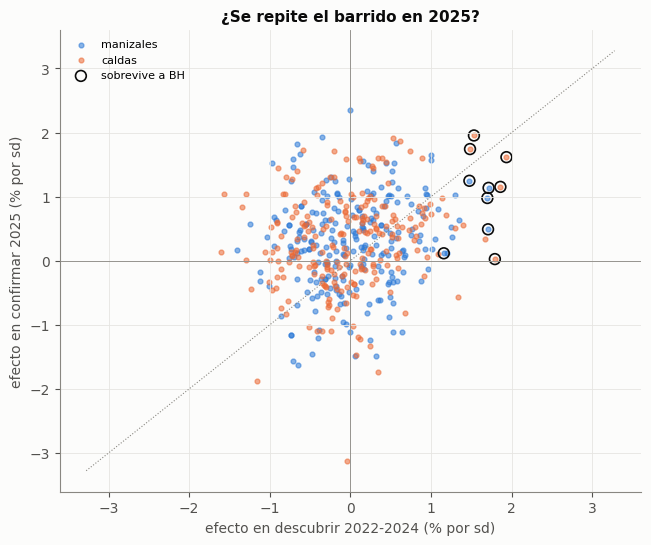

Con el desenlace sin su estación (sección 4b): r(descubrir, confirmar) = 0.05 | mismo signo: 52 %


pruebas           r desc-conf           mismo signo %           r desc-conf, y sin estación           mismo signo %, y sin estación          
ámbito              caldas manizales      caldas manizales        caldas manizales                      caldas manizales                        caldas manizales
familia                                                                                                                                                         
contagio              16.0      16.0       -0.14      0.08          50.0      56.0                       -0.45     -0.21                          25.0      50.0
crónico               32.0      32.0        0.21      0.12          66.0      44.0                       -0.39     -0.18                          34.0      41.0
gastro                56.0      56.0        0.50      0.35          82.0      84.0                        0.08     -0.09                          32.0      30.0
intoxicaciones        16.0      16.0        0.58      0.44          75.0      56.0                        0.62      0.36                          62.0      75.0
lesiones               8.0       8.0        0.38      0.17          38.0      62.0                        0.66      0.26                          62.0      38.0
materno                8.0       8.0        0.14     -0.44          75.0      25.0                        0.35     -0.21                          75.0      25.0
nutrición              8.0       8.0        0.27      0.37          88.0      88.0                       -0.10      0.44                          38.0      50.0
respiratorio          48.0      56.0        0.22      0.36          42.0      46.0                       -0.21     -0.32                          73.0      86.0
respiratorio grave    24.0      24.0        0.18      0.11          33.0      54.0                        0.06      0.03                          67.0      67.0
salud mental           8.0       8.0        0.18      0.44          38.0      75.0                        0.11      0.25                          38.0      62.0
violencia              8.0       8.0        0.26     -0.79          12.0      12.0                        0.24     -0.77                          50.0      38.0

In [8]:
filas = []
for (amb, nom), a in A.items():
    if amb == "colombia": continue
    a = a.reindex(yv.index)
    for k in REZ[1:]:
        sd = B[(B.ámbito == amb) & (B.serie == nom) & (B.rezago == k)].sd_desc.iloc[0]
        b, se, p, n, _ = ajuste(yv, a, k, CONF, sd=sd)
        filas.append({"ámbito": amb, "serie": nom, "rezago": k, "efecto % 2025": 100 * b, "p 2025": p})
        # Lo mismo con el desenlace sin su estación (sección 4b), en los dos periodos
        bd, *_r, sdd = ajuste(yv_des, a, k, DESC)
        bc, *_r = ajuste(yv_des, a, k, CONF, sd=sdd)
        filas[-1].update({"efecto % desc (y sin estación)": 100 * bd, "efecto % 2025 (y sin estación)": 100 * bc})
C = B[B.rezago.ge(1)].merge(pd.DataFrame(filas), on=["ámbito", "serie", "rezago"])
r_todo = C["efecto %"].corr(C["efecto % 2025"])
acuerdo = (np.sign(C["efecto %"]) == np.sign(C["efecto % 2025"])).mean()
fuertes = C[C.p < .05]
print(f"{len(C)} pruebas con rezago >= 1 | r(descubrir, confirmar) = {r_todo:.2f} | mismo signo: {100 * acuerdo:.0f} %")
print(f"Entre las {len(fuertes)} con p < 0,05 en descubrir: mismo signo en 2025 el {100 * (np.sign(fuertes['efecto %']) == np.sign(fuertes['efecto % 2025'])).mean():.0f} %")
fig, ax = plt.subplots(figsize=(7.5, 6))
for amb, col in [("manizales", AZUL), ("caldas", NARANJA)]:
    c = C[C.ámbito.eq(amb)]
    ax.scatter(c["efecto %"], c["efecto % 2025"], s=12, alpha=.55, color=col, label=amb)
s = C[C["sobrevive BH"]]
ax.scatter(s["efecto %"], s["efecto % 2025"], s=60, facecolors="none", edgecolors=TINTA, lw=1.2, label="sobrevive a BH")
lim = np.nanmax(np.abs(C[["efecto %", "efecto % 2025"]].values)) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=MUDO, lw=.8, ls=":"); ax.axhline(0, color=MUDO, lw=.6); ax.axvline(0, color=MUDO, lw=.6)
ax.set_xlabel("efecto en descubrir 2022-2024 (% por sd)"); ax.set_ylabel("efecto en confirmar 2025 (% por sd)")
ax.set_title("¿Se repite el barrido en 2025?"); ax.legend(fontsize=8); plt.show()
ye, ce = "efecto % desc (y sin estación)", "efecto % 2025 (y sin estación)"
print(f"Con el desenlace sin su estación (sección 4b): r(descubrir, confirmar) = {C[ye].corr(C[ce]):.2f} | "
      f"mismo signo: {100 * (np.sign(C[ye]) == np.sign(C[ce])).mean():.0f} %")
C.groupby(["ámbito", "familia"]).apply(lambda g: pd.Series({"pruebas": len(g), "r desc-conf": round(g["efecto %"].corr(g["efecto % 2025"]), 2),
                                                               "mismo signo %": round(100 * (np.sign(g["efecto %"]) == np.sign(g["efecto % 2025"])).mean()),
                                                               "r desc-conf, y sin estación": round(g[ye].corr(g[ce]), 2),
                                                               "mismo signo %, y sin estación": round(100 * (np.sign(g[ye]) == np.sign(g[ce])).mean())})).unstack(0)

## Lectura

**El barrido entero se repite poco: r = 0,18 entre los efectos de 2022-2024 y los de 2025, y el 58 % mantiene el signo** (el azar daría ~0 y 50 %). Entre las 46 pruebas con p < 0,05 en descubrir, el 74 % mantiene el signo.

Por familia, lo único que se repite con claridad es **gastro**: r = 0,50 en Caldas y 0,35 en Manizales, con el 82-84 % del signo igual. Lo respiratorio no se repite (42-46 % del signo). La violencia en Manizales **se invierte** (r = −0,79): lo que en 2022-2024 iba en una dirección, en 2025 va en la contraria.

**Pero con el desenlace sin su estación, la repetición desaparece: r = 0,05 y el 52 % del signo.** La familia gastro cae a 0,08 y −0,09, con el 30-32 % del signo igual. Lo que se repetía era la época del año, no la anomalía. Lo explica la sección 4b.

Lo único que mantiene algo sin estación son las **intoxicaciones** (r = 0,62 y 0,36), ninguna de cuyas pruebas pasó BH. Son además series con fuga posible. Queda anotado, sin más peso.

**Límite.** Las pruebas de una serie en rezagos vecinos no son independientes: los 472 puntos equivalen a muchos menos. Los porcentajes de signo son una lectura de conjunto, no una prueba.

---
# 4. Un índice general: la «presión epidemiológica» de la ciudad

Preregistrado (`indices_generales`): componentes principales de las anomalías de Manizales, **ajustados solo en descubrir** y proyectados en 2025. Al modelo entrarían índices, no decenas de series.

Qué series entran, y cuáles no:
- Se usan las **bandas de edad** de IRA y de EDA, no los totales, que serían su suma y pesarían doble.
- Fuera: la IRA sin SES (casi idéntica a la IRA total, ver sección 1), el cáncer (sin 2022), la tuberculosis pulmonar (es parte del 813) y la intoxicación por fármacos (es parte del 365).
- Cada serie se estandariza con la media y la desviación de descubrir.

157 semanas de ajuste, 24 series
Varianza explicada (%): {'PC1': 18.4, 'PC2': 11.2, 'PC3': 8.2, 'PC4': 6.5, 'PC5': 5.9, 'PC6': 5.2}
Parecido de las cargas con una PCA ajustada solo en 2025 (|r| con el componente más parecido): {'PC1': 0.66, 'PC2': 0.73, 'PC3': 0.54, 'PC4': 0.43}
Varianza que conserva cada componente proyectado en 2025 (%): {'PC1': 11.7, 'PC2': 9.4, 'PC3': 6.0, 'PC4': 4.0}


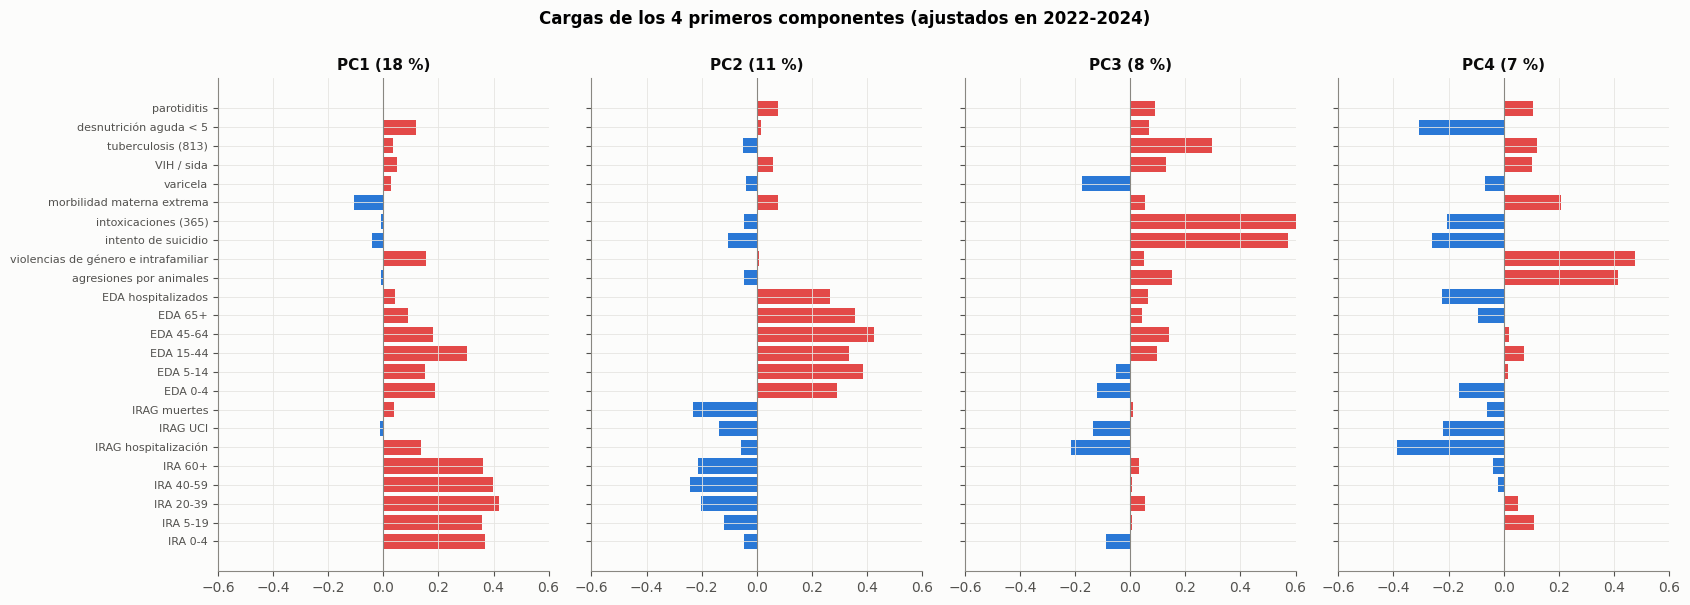

,PC1,PC2,PC3,PC4
IRA 0-4,0.37,-0.05,-0.09,0.00
IRA 5-19,0.36,-0.12,0.01,0.11
IRA 20-39,0.42,-0.20,0.05,0.05
IRA 40-59,0.40,-0.24,0.01,-0.02
IRA 60+,0.36,-0.21,0.03,-0.04
IRAG hospitalización,0.14,-0.06,-0.21,-0.39
IRAG UCI,-0.01,-0.14,-0.13,-0.22
IRAG muertes,0.04,-0.23,0.01,-0.06
EDA 0-4,0.19,0.29,-0.12,-0.16
EDA 5-14,0.15,0.39,-0.05,0.02


In [9]:
EN_PCA = [f"IRA {b.replace('_', '-').replace('-mas', '+')}" for b in BANDAS_IRA] + ["IRAG hospitalización", "IRAG UCI", "IRAG muertes"] + \
         [f"EDA {b.replace('_', '-').replace('-mas', '+')}" for b in BANDAS_EDA] + ["EDA hospitalizados"] + \
         [NOMBRE_EV[e] for e in (300, 875, 356, 365, 549, 831, 850, 813, 113, 620)]
X = pd.DataFrame({n: A[("manizales", n)] for n in EN_PCA})
Xd = X.loc["2022-01-02":DESC[1]].dropna()
mu, sd = Xd.mean(), Xd.std()
pca = PCA(n_components=6).fit(((Xd - mu) / sd).values)
carg = pd.DataFrame(pca.components_.T, index=EN_PCA, columns=[f"PC{i+1}" for i in range(6)])
signo = np.sign(carg.apply(lambda c: c[c.abs().idxmax()]))           # la carga mayor, positiva
carg = carg * signo
Z = pd.DataFrame(((X.dropna() - mu) / sd).values @ carg.values, index=X.dropna().index, columns=carg.columns)
print(f"{len(Xd)} semanas de ajuste, {len(EN_PCA)} series")
print("Varianza explicada (%):", dict(zip(carg.columns, (100 * pca.explained_variance_ratio_).round(1))))
# Estabilidad: la misma PCA ajustada en 2025, ¿da las mismas cargas?
Xc = X.loc[CONF[0]:CONF[1]].dropna()
pca_c = PCA(n_components=4).fit(((Xc - Xc.mean()) / Xc.std()).values)
estab = {f"PC{i+1}": round(max(abs(np.corrcoef(carg[f'PC{i+1}'], pca_c.components_[j])[0, 1]) for j in range(4)), 2) for i in range(4)}
print("Parecido de las cargas con una PCA ajustada solo en 2025 (|r| con el componente más parecido):", estab)
var_conf = {c: round(100 * Z.loc[CONF[0]:CONF[1], c].var() / (((Xc - mu) / sd).var().sum()), 1) for c in carg.columns[:4]}
print("Varianza que conserva cada componente proyectado en 2025 (%):", var_conf)
fig, axes = plt.subplots(1, 4, figsize=(17, 6), sharey=True)
for ax, c in zip(axes, carg.columns[:4]):
    v = carg[c]
    ax.barh(range(len(v)), v.values, color=[ROJO if x > 0 else AZUL for x in v.values])
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(f"{c} ({100 * pca.explained_variance_ratio_[int(c[2:]) - 1]:.0f} %)")
    ax.set_yticks(range(len(v)), v.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(-.6, .6)
plt.suptitle("Cargas de los 4 primeros componentes (ajustados en 2022-2024)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()
carg.iloc[:, :4].round(2)

## Lectura

**La salud de la ciudad no tiene un eje dominante.** 24 series, 157 semanas de ajuste (2022-01 a 2024-12). Los 4 primeros componentes explican el **44 %** de la varianza (18,4 + 11,2 + 8,2 + 6,5):

| Componente | Varianza | Cargas altas | Nombre | ¿Estable en 2025? |
|---|---|---|---|---|
| **PC1** | 18,4 % | Las 5 bandas de IRA (0,36-0,42), EDA 15-44 (0,30) | **Respiratorio de la ciudad** | Parecido 0,66; conserva 11,7 % |
| **PC2** | 11,2 % | Las 5 bandas de EDA (0,29-0,43), EDA hospitalizada (0,26), contra IRA e IRAG (−0,20 a −0,24) | **Gastro, en contra de lo respiratorio** | Parecido 0,73; conserva 9,4 % |
| **PC3** | 8,2 % | Intoxicaciones (0,60), intento de suicidio (0,57), tuberculosis (0,30) | **Salud mental e intoxicaciones** | Parecido 0,54; conserva 6,0 % |
| **PC4** | 6,5 % | Violencias (0,48), agresiones por animales (0,41), contra IRAG hospitalizada (−0,39) y desnutrición (−0,31) | **Violencia y lesiones** | Parecido 0,43; conserva 4,0 % |

- **PC1 y PC2 son reconocibles y bastante estables.** Son las dos grandes familias de circulación comunitaria: la respiratoria y la gastrointestinal. PC2 las opone: las semanas con más EDA de lo normal tienden a tener menos IRA.
- **PC3 y PC4 son frágiles.** Una PCA ajustada solo en 2025 las reproduce a medias (0,54 y 0,43). Juntan eventos de pocas decenas de casos por semana, donde el ruido de conteo pesa mucho.
- Lo grave (IRAG UCI y muertes) no tiene componente propio: carga poco en todos.

**Límite.** «Parecido» es la correlación de las cargas con el componente más parecido de una PCA de 2025, que tiene solo 52 semanas. Es orientativo.

## Los componentes contra el triage y contra sus desenlaces específicos

Cada componente, con rezagos de 0 a 8, contra `y` y contra los desenlaces secundarios del cuaderno 10 (`y_respiratorio`, `y_infecciosas`, `y_trauma`), en descubrir. BH con q = 0,10 sobre esta familia (4 componentes × 4 desenlaces × 9 rezagos). El rezago 0 entra en la familia pero no cuenta. Lo que sobrevive se confirma en 2025 con el mismo criterio de antes.

Pruebas: 144 | sobreviven a BH: 10 (rezago >= 1: 8) | confirmadas en 2025: 1
Contra y (triage total), efecto máximo en valor absoluto, % por sd: {'PC1': 1.71, 'PC2': 1.2, 'PC3': 1.19, 'PC4': 1.05}


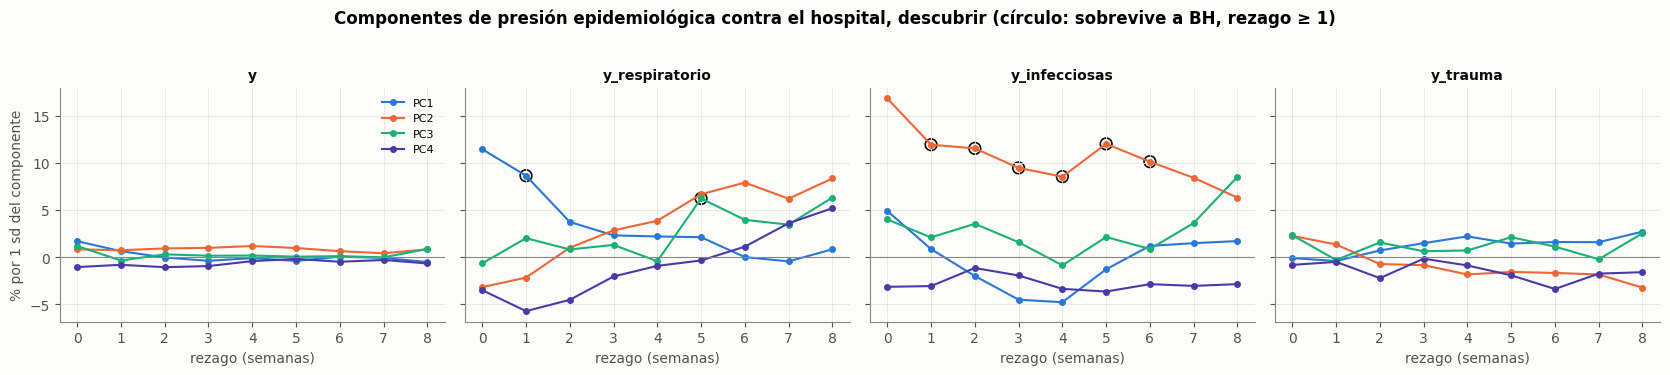

,desenlace,componente,rezago,efecto %,p,efecto % 2025,p unilateral 2025,q,sobrevive BH,confirmada
0,y_infecciosas,PC2,0,16.848,0.001,2.278,0.375,0.023,True,False
1,y_infecciosas,PC2,1,11.942,0.006,4.766,0.198,0.080,True,False
2,y_infecciosas,PC2,2,11.554,0.000,-0.427,0.530,0.023,True,False
3,y_infecciosas,PC2,3,9.481,0.001,-3.548,0.707,0.025,True,False
4,y_infecciosas,PC2,4,8.556,0.005,-4.351,0.723,0.080,True,False
5,y_infecciosas,PC2,5,12.031,0.001,2.253,0.344,0.023,True,False
6,y_infecciosas,PC2,6,10.142,0.004,2.205,0.344,0.080,True,False
7,y_respiratorio,PC1,0,11.466,0.000,14.439,0.012,0.001,True,False
8,y_respiratorio,PC1,1,8.656,0.002,10.609,0.055,0.053,True,False
9,y_respiratorio,PC3,5,6.240,0.003,9.141,0.005,0.071,True,True


In [10]:
DESENLACES = [c for c in ["y", "y_respiratorio", "y_infecciosas", "y_trauma"] if c in Y.columns]
filas = []
for des in DESENLACES:
    yy = Y[des].reindex(yv.index)
    for c in carg.columns[:4]:
        z = Z[c].reindex(yv.index)
        for k in REZ:
            b, se, p, n, sdz = ajuste(yy, z, k, DESC)
            b2, se2, p2, n2, _ = ajuste(yy, z, k, CONF, sd=sdz)
            filas.append({"desenlace": des, "componente": c, "rezago": k, "efecto %": 100 * b, "p": p,
                          "efecto % 2025": 100 * b2, "p unilateral 2025": p2 / 2 if np.sign(b2) == np.sign(b) else 1 - p2 / 2})
P = pd.DataFrame(filas)
P["q"] = multipletests(P.p, method="fdr_bh")[1]
P["sobrevive BH"] = P.q < q_BH
P["confirmada"] = P["sobrevive BH"] & P.rezago.ge(1) & (P["p unilateral 2025"] < .05)
print(f"Pruebas: {len(P)} | sobreviven a BH: {P['sobrevive BH'].sum()} (rezago >= 1: {(P['sobrevive BH'] & P.rezago.ge(1)).sum()}) "
      f"| confirmadas en 2025: {P.confirmada.sum()}")
print("Contra y (triage total), efecto máximo en valor absoluto, % por sd:",
      P[P.desenlace.eq("y")].groupby("componente")["efecto %"].apply(lambda s: round(s.abs().max(), 2)).to_dict())
fig, axes = plt.subplots(1, len(DESENLACES), figsize=(4.2 * len(DESENLACES), 3.6), sharey=True)
for ax, des in zip(np.atleast_1d(axes), DESENLACES):
    for c, col in zip(carg.columns[:4], [AZUL, NARANJA, AQUA, VIOLETA]):
        p_ = P[(P.desenlace == des) & (P.componente == c)]
        ax.plot(p_.rezago, p_["efecto %"], marker="o", ms=4, color=col, label=c)
        s_ = p_[p_["sobrevive BH"] & p_.rezago.ge(1)]
        ax.scatter(s_.rezago, s_["efecto %"], s=70, facecolors="none", edgecolors=TINTA, lw=1.2)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(des, fontsize=10); ax.set_xlabel("rezago (semanas)")
np.atleast_1d(axes)[0].set_ylabel("% por 1 sd del componente"); np.atleast_1d(axes)[0].legend(fontsize=8)
plt.suptitle("Componentes de presión epidemiológica contra el hospital, descubrir (círculo: sobrevive a BH, rezago ≥ 1)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
P[P["sobrevive BH"] | P.confirmada].round(3).sort_values(["desenlace", "componente", "rezago"]).reset_index(drop=True)

## Lectura

**Contra el triage total, ningún componente pasa de ±1,7 % por desviación típica** (PC1 1,71; PC2 1,20; PC3 1,19; PC4 1,05), y nada sobrevive a BH. La presión epidemiológica de la ciudad **no mueve el total del hospital de forma visible**.

**Contra los desenlaces específicos sí se ve, y con tamaño.** De 144 pruebas sobreviven 10 (8 con rezago ≥ 1):

| Componente → desenlace | Rezago | Descubrir | 2025 | Lectura |
|---|---|---|---|---|
| **PC1 (respiratorio) → respiratorio del hospital** | 0 | **+11,5 %** | **+14,4 %** (p 0,012) | La ola de la ciudad y la del hospital van juntas. **No cuenta**: rezago 0 |
| **PC1 → respiratorio** | **1** | **+8,7 %** (q 0,053) | **+10,6 %** (p 0,055) | Mismo signo y tamaño; **se queda justo fuera** del criterio (0,055 contra 0,05) |
| PC2 (gastro) → infecciosas | 1 a 6 | +8,6 a +12,0 % | −4,4 a +4,8 % | No se repite |
| PC3 (salud mental) → respiratorio | 5 | +6,2 % | +9,1 % (p 0,005) | **Confirmado**, sin mecanismo: sección 4b |

- **Aquí está el argumento de dilución de `CLAUDE.md`, medido.** Una desviación típica de ola respiratoria en la ciudad va con ~+11 a +14 % de consultas respiratorias en el hospital esa misma semana, y con menos de +2 % del total. El efecto existe, pero **se diluye en el total**.
- **PC1 a 1 semana** es el único resultado con mecanismo claro (contagio comunitario → consulta), el mismo tamaño en los dos periodos y el mismo signo. No pasa el criterio fijado (p 0,055 contra 0,05). No se da por confirmado; se deja **como el candidato mejor situado**.
- **La gastro de la ciudad no anticipa las infecciosas del hospital en 2025**, pese a +9 a +12 % en descubrir.

**Límite.** Los desenlaces específicos salen de los diagnósticos del cuaderno 10 (`salidas/perfil_dx_diario.parquet`, local). Son más ruidosos que el total y su codificación puede haber cambiado entre años.

---
# 4b. Lo confirmado, ¿anticipa o solo acompaña a la estación?

**Esta prueba no estaba preregistrada**: se añade después de ver que lo confirmado se repite en rezagos contiguos (3, 4, 5, 6 semanas), que es la firma de dos series que se mueven juntas despacio, no la de un gatillo con su reloj. Dos preguntas para cada resultado confirmado:

1. **Rezagos negativos.** Si el **triage** «predice» la serie de vigilancia tan bien como la serie predice el triage, las dos se mueven juntas: nadie va antes.
2. **Desenlace sin su estación.** El desenlace conserva la estacionalidad a propósito (`desenlace.py`). Pero la anomalía de vigilancia solo quita la forma estacional **típica de 2015-2024**; si la forma de los años recientes es otra, a la anomalía le queda algo de estación y puede empatar con la del hospital. Se repite la prueba con el desenlace sin su propia forma estacional (3 armónicos ajustados en descubrir). Si el efecto se va, lo que explicaba era **la época del año**, que ya se conoce por calendario: eso es proyección, no predicción.

4 resultados confirmados que revisar


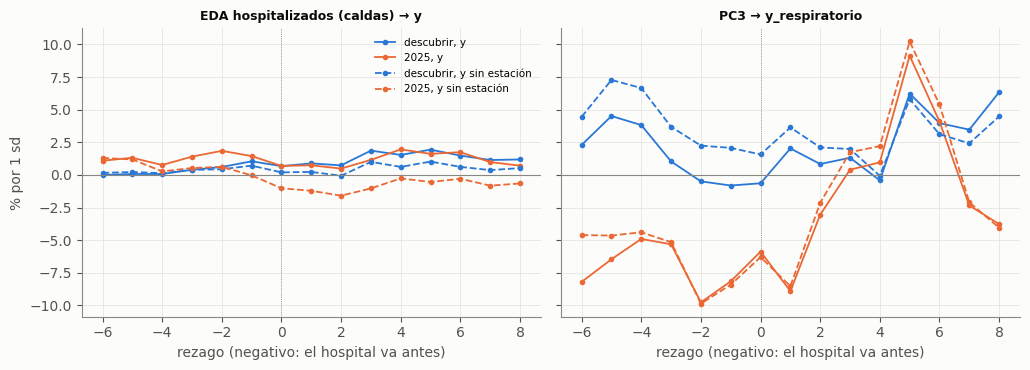

resultado confirmado,EDA hospitalizados (caldas) → y,EDA hospitalizados (caldas) → y,EDA hospitalizados (caldas) → y,PC3 → y_respiratorio
rezago,4.000,5.000,6.000,5.000
"y, desc: efecto %",1.530,1.940,1.480,6.240
"y, desc: p",0.001,0.000,0.002,0.003
"y, 2025: efecto %",1.960,1.620,1.740,9.140
"y, 2025: p",0.028,0.055,0.005,0.010
"y sin estación, desc: efecto %",0.610,1.020,0.620,5.810
"y sin estación, desc: p",0.064,0.014,0.097,0.005
"y sin estación, 2025: efecto %",-0.270,-0.540,-0.300,10.230
"y sin estación, 2025: p",0.734,0.485,0.682,0.002
triage antes (2025): mejor rezago,-2.000,-2.000,-2.000,-6.000


In [11]:
confirmados = []
if len(SOB):
    for _, r in SOB[SOB.confirmada].iterrows():
        confirmados.append((f"{r.serie} ({r.ámbito}) → y", A[(r.ámbito, r.serie)], "y", r.rezago))
for _, r in P[P.confirmada].iterrows():
    confirmados.append((f"{r.componente} → {r.desenlace}", Z[r.componente], r.desenlace, r.rezago))
filas, curvas = [], {}
for etiqueta, x, des, k in confirmados:
    yy = Y[des].reindex(yv.index); yd = sin_estacion(yy); x = x.reindex(yv.index)
    fila = {"resultado confirmado": etiqueta, "rezago": k}
    for nom_y, serie_y in [("y", yy), ("y sin estación", yd)]:
        for per_nom, per in [("desc", DESC), ("2025", CONF)]:
            sdx = ajuste(serie_y, x, k, DESC)[4]
            b, se, p2, n, _ = ajuste(serie_y, x, k, per, sd=sdx)
            fila[f"{nom_y}, {per_nom}: efecto %"] = round(100 * b, 2)
            fila[f"{nom_y}, {per_nom}: p"] = round(p2, 3)
    neg = [(j, *ajuste(yy, x, -j, CONF, sd=ajuste(yy, x, -j, DESC)[4])[:3]) for j in range(1, 7)]
    j, b, se, p = min(neg, key=lambda t: t[3])
    fila["triage antes (2025): mejor rezago"] = -j; fila["triage antes (2025): efecto %"] = round(100 * b, 2); fila["triage antes (2025): p"] = round(p, 3)
    filas.append(fila)
    curvas[etiqueta] = pd.DataFrame({per_nom: {kk: 100 * ajuste(sy, x, kk, per, sd=ajuste(sy, x, kk, DESC)[4])[0] for kk in range(-6, 9)}
                                     for per_nom, per, sy in [("descubrir, y", DESC, yy), ("2025, y", CONF, yy),
                                                              ("descubrir, y sin estación", DESC, yd), ("2025, y sin estación", CONF, yd)]})
print(f"{len(confirmados)} resultados confirmados que revisar")
if curvas:
    fig, axes = plt.subplots(1, len(curvas), figsize=(5.2 * len(curvas), 3.8), sharey=True)
    for ax, (et, cu) in zip(np.atleast_1d(axes), curvas.items()):
        for c, col, ls in [("descubrir, y", AZUL, "-"), ("2025, y", NARANJA, "-"), ("descubrir, y sin estación", AZUL, "--"), ("2025, y sin estación", NARANJA, "--")]:
            ax.plot(cu.index, cu[c], color=col, ls=ls, marker="o", ms=3, lw=1.3, label=c)
        ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
        ax.set_title(et, fontsize=9); ax.set_xlabel("rezago (negativo: el hospital va antes)")
    np.atleast_1d(axes)[0].set_ylabel("% por 1 sd"); np.atleast_1d(axes)[0].legend(fontsize=7.5)
    plt.tight_layout(); plt.show()
pd.DataFrame(filas).set_index("resultado confirmado").T

In [12]:
# Cuántas confirmaciones daría el azar, y de qué está hecho cada componente confirmado
n_prob_barr, n_prob_pca = len(SOB), int((P["sobrevive BH"] & P.rezago.ge(1)).sum())
print(f"Confirmaciones esperadas por azar (p unilateral < 0,05): barrido {0.05 * n_prob_barr:.1f} de {n_prob_barr}; "
      f"componentes {0.05 * n_prob_pca:.1f} de {n_prob_pca}")
filas = []
for _, r in P[P.confirmada].iterrows():
    yy = Y[r.desenlace].reindex(yv.index)
    for n in carg[r.componente].abs().sort_values(ascending=False).index[:6]:
        x = A[("manizales", n)].reindex(yv.index)
        b, _, p, _, sdx = ajuste(yy, x, r.rezago, DESC); b2, _, p2, _, _ = ajuste(yy, x, r.rezago, CONF, sd=sdx)
        filas.append({"componente → desenlace": f"{r.componente} → {r.desenlace}, rezago {r.rezago}", "serie": n,
                      "carga": round(carg.loc[n, r.componente], 2), "efecto % desc": round(100 * b, 1), "p desc": round(p, 3),
                      "efecto % 2025": round(100 * b2, 1), "p 2025": round(p2, 3)})
pd.DataFrame(filas).set_index(["componente → desenlace", "serie"]) if filas else "ningún componente confirmado"

Confirmaciones esperadas por azar (p unilateral < 0,05): barrido 0.5 de 10; componentes 0.4 de 8


carga  efecto % desc  p desc  efecto % 2025  p 2025
componente → desenlace         serie                                                                       
PC3 → y_respiratorio, rezago 5 intoxicaciones (365)      0.60            3.9   0.071            8.9   0.007
                               intento de suicidio       0.57            2.9   0.251            6.0   0.061
                               tuberculosis (813)        0.30            0.2   0.947           -3.0   0.427
                               IRAG hospitalización     -0.21           -2.9   0.361          -13.4   0.002
                               varicela                 -0.17           -3.7   0.270            9.6   0.001
                               agresiones por animales   0.15            0.7   0.774           -6.9   0.037

## Lectura

**Ninguno de los 4 resultados confirmados resiste. Lo confirmado no es anticipación.**

**1. EDA hospitalizados de Caldas → triage (rezagos 4, 5 y 6): acompaña a la estación, no la anticipa.**
- Con el desenlace sin su estación, el efecto en 2025 pasa de +1,6 a +2,0 % a **−0,3 a −0,5 %** (p 0,48-0,73). En descubrir también se encoge a la mitad o menos (+0,6 a +1,0 %).
- En 2025, el **triage** «predice» la EDA hospitalizada 2 semanas después casi igual (+1,84 %, p 0,031). Las dos series se mueven juntas, despacio; ninguna va antes.
- Por qué queda estación en la anomalía [I]: la EDA hospitalizada **casi se duplicó** entre 2019 y 2024 (sección 1) mientras la EDA total caía. La forma estacional típica se ajustó con años en que la serie era otra cosa, así que a la anomalía le queda la época del año de los años recientes, y esa coincide con la del hospital.
- **Consecuencia:** explica la época del año, que ya da el calendario. Es proyección, no predicción.

**2. PC3 (salud mental e intoxicaciones) → respiratorio del hospital (rezago 5): azar con apariencia de hallazgo.**
- Sí resiste la prueba de estación (+10,2 % en 2025, p 0,002), pero:
  - **ninguna de sus series lo lleva en descubrir**: intoxicaciones +3,9 % (p 0,071), intento de suicidio +2,9 % (p 0,25), tuberculosis +0,2 %;
  - **en 2025 lo llevan otras series, con signos que no cuadran**: la hospitalización por IRAG va a −13,4 % y la varicela a +9,6 %;
  - la curva de 2025 cambia de signo entre rezagos vecinos (figura): no tiene la forma de un reloj;
  - no hay mecanismo por el que los intentos de suicidio anticipen consultas respiratorias 5 semanas después;
  - de las 8 pruebas de componentes que se llevaron a 2025, **el azar daría 0,4 confirmaciones**. Una es lo esperable.

**Por qué esta sección importa para el sobreajuste.** Con el criterio preregistrado, el cuaderno habría dado por buenos dos «predictores». Los dos caen con una sola pregunta más: **¿va antes, o solo va a la vez?** Es la defensa que pedía el propietario, y queda como parte del método para los cuadernos siguientes: **ningún resultado confirmado entra sin la prueba de estación y la de rezagos negativos.**

---
# 5. ¿La ciudad anticipa al departamento, o al revés?

IRA y EDA de Manizales frente a **Caldas sin Manizales** (Caldas incluye a Manizales, y compararla consigo misma daría una correlación mecánica) y frente a **Colombia**. Dos miradas, en anomalía, 2022-2025:
1. **Correlación cruzada** con rezagos de −8 a +8 semanas. Un pico en rezago positivo quiere decir que la otra geografía va **antes** que Manizales.
2. **Prueba de precedencia (tipo Granger), con errores HAC:** ¿las 2 semanas previas de Caldas o de Colombia mejoran la predicción de Manizales cuando ya se tienen sus propias 2 semanas previas? Y al revés.

Una salvedad: las tres geografías comparten el calendario nacional (Semana Santa, festivos), que mueve la consulta la misma semana en todas partes. Por eso el rezago 0 alto no dice quién va antes.

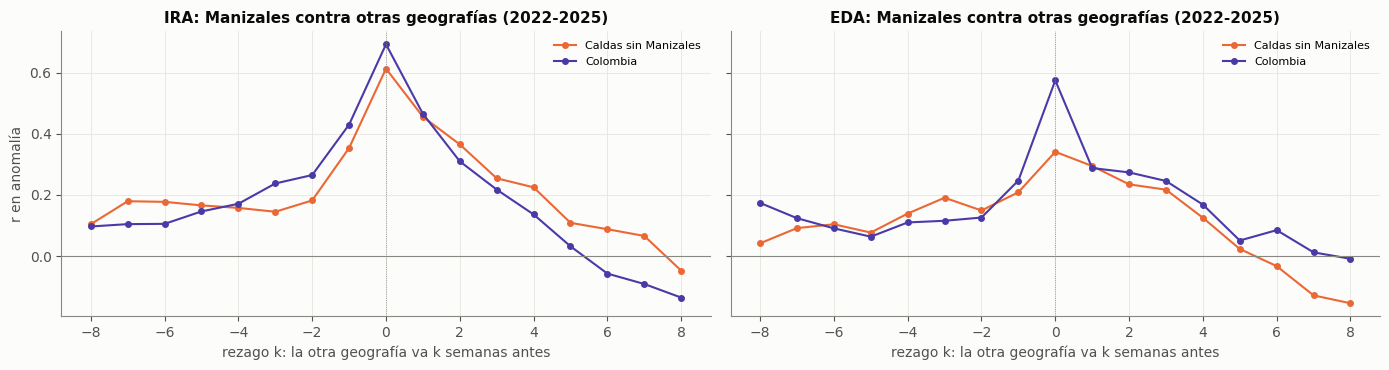

,serie,sentido,r rezago 0,r mejor rezago,mejor rezago,coef. semana previa,p precedencia (HAC),semanas
0,IRA,Caldas sin Manizales → Manizales,0.61,0.61,0,0.150,0.0089,207
1,IRA,Manizales → Caldas sin Manizales,0.61,0.61,0,0.068,0.5512,207
2,IRA,Colombia → Manizales,0.69,0.69,0,0.282,0.2453,207
3,IRA,Manizales → Colombia,0.69,0.69,0,-0.045,0.5860,207
4,EDA,Caldas sin Manizales → Manizales,0.34,0.34,0,0.163,0.1032,206
5,EDA,Manizales → Caldas sin Manizales,0.34,0.34,0,0.044,0.6997,206
6,EDA,Colombia → Manizales,0.58,0.58,0,-0.031,0.5522,206
7,EDA,Manizales → Colombia,0.58,0.58,0,0.004,0.5721,207


In [13]:
def resta(a, b): return (a - b).where((a - b) > 0)
pares = {}
for nom, ev, var in [("IRA", 995, "consultas_ira_total"), ("EDA", 998, "casos_eda_total")]:
    man = serie("manizales", ev, var); cal = serie("caldas", ev, var); col = serie("colombia", ev, var)
    pares[nom] = {"Manizales": anomalia(man), "Caldas sin Manizales": anomalia(resta(cal, man)), "Colombia": anomalia(col)}
K = range(-8, 9)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True); filas = []
for ax, (nom, d) in zip(axes, pares.items()):
    m = d["Manizales"].loc["2022":"2025"]
    for otro, col in [("Caldas sin Manizales", NARANJA), ("Colombia", VIOLETA)]:
        o = d[otro]
        rs = [m.corr(o.shift(k).reindex(m.index)) for k in K]
        ax.plot(list(K), rs, marker="o", ms=4, color=col, label=otro)
        # precedencia
        D = pd.DataFrame({"m": m, "o": o.reindex(m.index)})
        for sentido, (dep, ind) in {f"{otro} → Manizales": ("m", "o"), f"Manizales → {otro}": ("o", "m")}.items():
            Xg = pd.DataFrame({"c": 1.0, "p1": D[dep].shift(1), "p2": D[dep].shift(2), "x1": D[ind].shift(1), "x2": D[ind].shift(2)})
            dd = pd.concat([D[dep].rename("dep"), Xg], axis=1).dropna()
            g = sm.OLS(dd.dep, dd.drop(columns="dep")).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            w = g.wald_test("x1 = 0, x2 = 0", scalar=True)
            filas.append({"serie": nom, "sentido": sentido, "r rezago 0": round(rs[8], 2),
                          "r mejor rezago": round(max(rs, key=abs), 2), "mejor rezago": list(K)[int(np.argmax(np.abs(rs)))],
                          "coef. semana previa": round(g.params["x1"], 3), "p precedencia (HAC)": round(float(w.pvalue), 4), "semanas": len(dd)})
    ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
    ax.set_title(f"{nom}: Manizales contra otras geografías (2022-2025)"); ax.set_xlabel("rezago k: la otra geografía va k semanas antes")
    ax.legend(fontsize=8)
axes[0].set_ylabel("r en anomalía"); plt.tight_layout(); plt.show()
pd.DataFrame(filas)

## Lectura

**La ciudad, el resto del departamento y el país enferman a la vez. Para la IRA, el resto de Caldas va un poco antes que Manizales; al revés, no.**

| | r a la vez | Mejor rezago | Otra → Manizales (p) | Manizales → otra (p) |
|---|---|---|---|---|
| IRA, Caldas sin Manizales | 0,61 | 0 | **0,009** (coef. 0,15) | 0,55 |
| IRA, Colombia | 0,69 | 0 | 0,25 | 0,59 |
| EDA, Caldas sin Manizales | 0,34 | 0 | 0,10 | 0,70 |
| EDA, Colombia | 0,58 | 0 | 0,55 | 0,57 |

- **La correlación más alta es siempre a la vez** (rezago 0). Es el calendario nacional compartido y la circulación simultánea.
- **Pero la IRA del resto de Caldas añade información sobre la de Manizales de la semana siguiente**, aun sabiendo las dos semanas previas de Manizales (p = 0,009). En sentido contrario, nada (p = 0,55). Es una precedencia **pequeña**: 0,15 de cada unidad de anomalía pasa a Manizales una semana después. Encaja con un contagio que llega a la capital desde los municipios, o con una notificación más rápida fuera de Manizales; con estos datos no se separa.
- **Colombia no anticipa a Manizales** en la IRA (p = 0,25) ni en la EDA. Va a la vez.
- La EDA del departamento se parece poco a la de la ciudad (0,34): la diarrea es más local, por brotes.

**Límite.** 2022-2025, 206-207 semanas. Es una sola prueba por par, no corregida por multiplicidad (8 pruebas: con Bonferroni, 0,009 × 8 = 0,07).

## ¿Y el departamento anticipa al hospital?

Lo que importa al final no es si Caldas anticipa a Manizales, sino si **anticipa al triage** mejor que la propia ciudad. Mismo barrido que en la sección 2, IRA y EDA de Caldas sin Manizales y de Colombia, rezagos 1 a 8, en descubrir y en 2025. Es exploratorio: no estaba en la familia preregistrada, y se lee solo al lado de la IRA de Manizales.

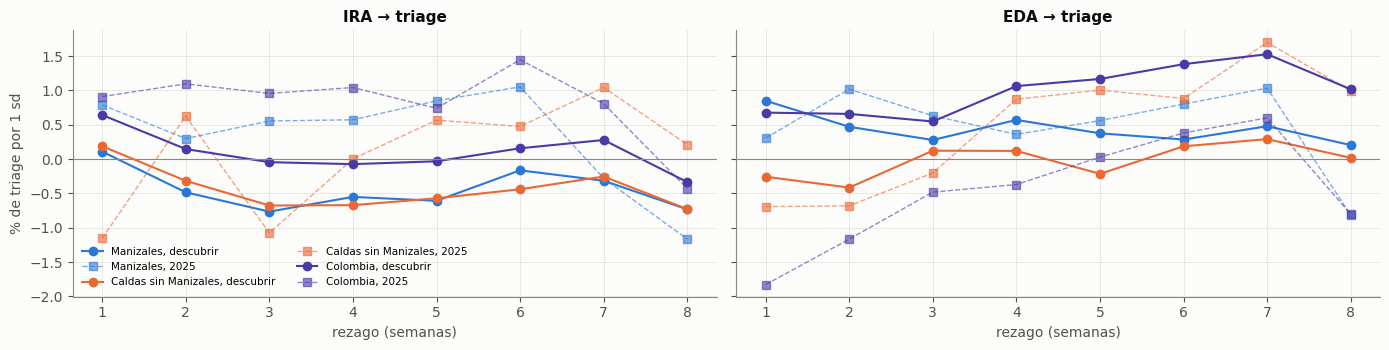

efecto % desc (rango)  p mínima desc  rezago de p mínima  efecto % 2025 en ese rezago  BH (q) de la p mínima, 48 pruebas
serie geografía                                                                                                                                    
EDA   Caldas sin Manizales         -0.42 a +0.29          0.447                   2                        -0.68                              0.937
      Colombia                     +0.55 a +1.53          0.003                   7                         0.60                              0.156
      Manizales                    +0.20 a +0.85          0.102                   1                         0.31                              0.812
IRA   Caldas sin Manizales         -0.73 a +0.19          0.226                   8                         0.21                              0.937
      Colombia                     -0.34 a +0.64          0.360                   1                         0.91                              0.937
      Manizales                    -0.77 a +0.11          0.217                   8                        -1.16                              0.937

In [14]:
filas = []
fuentes = {("IRA", "Manizales"): pares["IRA"]["Manizales"], ("IRA", "Caldas sin Manizales"): pares["IRA"]["Caldas sin Manizales"],
           ("IRA", "Colombia"): pares["IRA"]["Colombia"], ("EDA", "Manizales"): pares["EDA"]["Manizales"],
           ("EDA", "Caldas sin Manizales"): pares["EDA"]["Caldas sin Manizales"], ("EDA", "Colombia"): pares["EDA"]["Colombia"]}
for (nom, geo), a in fuentes.items():
    a = a.reindex(yv.index)
    for k in REZ[1:]:
        b, se, p, n, sdx = ajuste(yv, a, k, DESC)
        b2, _, p2, _, _ = ajuste(yv, a, k, CONF, sd=sdx)
        filas.append({"serie": nom, "geografía": geo, "rezago": k, "efecto % desc": 100 * b, "p desc": p, "efecto % 2025": 100 * b2, "p 2025": p2})
G = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, nom in zip(axes, ["IRA", "EDA"]):
    for geo, col in [("Manizales", AZUL), ("Caldas sin Manizales", NARANJA), ("Colombia", VIOLETA)]:
        g = G[(G.serie == nom) & (G.geografía == geo)]
        ax.plot(g.rezago, g["efecto % desc"], marker="o", color=col, label=f"{geo}, descubrir")
        ax.plot(g.rezago, g["efecto % 2025"], marker="s", ls="--", lw=1, color=col, alpha=.6, label=f"{geo}, 2025")
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(f"{nom} → triage"); ax.set_xlabel("rezago (semanas)")
axes[0].set_ylabel("% de triage por 1 sd"); axes[0].legend(fontsize=7.5, ncol=2); plt.tight_layout(); plt.show()
res = G.groupby(["serie", "geografía"]).apply(lambda g: pd.Series({
    "efecto % desc (rango)": f"{g['efecto % desc'].min():+.2f} a {g['efecto % desc'].max():+.2f}",
    "p mínima desc": round(g["p desc"].min(), 3), "rezago de p mínima": int(g.loc[g["p desc"].idxmin(), "rezago"]),
    "efecto % 2025 en ese rezago": round(g.loc[g["p desc"].idxmin(), "efecto % 2025"], 2),
    "BH (q) de la p mínima, 48 pruebas": None}))
qG = pd.Series(multipletests(G["p desc"], method="fdr_bh")[1], index=G.index)
res["BH (q) de la p mínima, 48 pruebas"] = G.assign(q=qG).groupby(["serie", "geografía"]).q.min().round(3)
res

## Lectura

**Que el resto de Caldas vaya antes que Manizales no lo convierte en un indicador del hospital.** Ninguna geografía anticipa el triage total. En 48 pruebas (2 series × 3 geografías × 8 rezagos), ninguna sobrevive a BH:

- **IRA**, de cualquier geografía: entre −0,77 y +0,64 % de triage por desviación típica. Nada.
- **EDA de Colombia**: +0,55 a +1,53 % en todos los rezagos, con p mínima 0,003 a 7 semanas (q = 0,16), y +0,60 % en 2025 en ese rezago. Es la única con un signo constante. No llega al umbral, y 7 semanas de rezago desde el país hacia un hospital local no tienen mecanismo evidente.
- **EDA del resto de Caldas**: nada (−0,42 a +0,29 %).

**Lectura para el pronóstico.** La precedencia Caldas → Manizales sirve para **anticipar la IRA de la ciudad**, que a su vez va con el respiratorio del hospital (sección 4). Es una cadena de dos eslabones y cada uno es pequeño. No se añade como variable: si algún día entra la IRA de la ciudad, el resto de Caldas sería su adelanto, no un predictor aparte.

---
# 6. El rezago de publicación: qué se puede calcular a tiempo

Una serie solo sirve para **pronosticar** si su valor de la semana `t − k` ya está publicado cuando se pronostica la semana `t`. Las fuentes (`FUENTES_VIGILANCIA.md`):

| Fuente | Rezago | Qué trae | Geografía |
|---|---|---|---|
| Microdatos del INS | **~8 meses** tras el cierre del año (2025 salió en agosto de 2026) | Todo lo de este cuaderno | Todas |
| Power BI 006 «Vigilancia rutinaria» | **~7 días** + notificación tardía de 2-3 semanas | Eventos individuales por semana; IRA 995 total, IRAG, UCI | Manizales (congelado); el tablero tiene municipio |
| Power BI 995 «Morbilidad por IRA» | ~7 días | IRA por edad con denominador, por institución | Manizales; **nivel +3 a +8 % sobre los microdatos** |
| Power BI por evento (300, 356, 831, 875) | ~7 días | Casos por semana | Manizales |
| BES del INS (PDF) | ~6 días | Acumulados por departamento | Caldas, raspado frágil |
| EDA 998 en Power BI | ~7 días | Existe, **no descargado**: el filtro de municipio no se validó | — |

Consecuencias:
- **Con los microdatos no se pronostica nada**: sirven para descubrir y medir.
- Con Power BI, el último dato firme es de **2-3 semanas atrás** (la última semana llega incompleta y se corrige). Un rezago de 1 semana queda en el borde; **de 3 semanas en adelante es operativo**.
- La anomalía necesita la media del año: en operación hay que sustituirla por una media móvil hacia atrás.
- Hoy hay **una sola instantánea** de Power BI (28-09-2026). Sin congelar una cada semana, no se puede reconstruir qué se sabía en cada fecha.

Prueba práctica: con la instantánea de Power BI se calcula la anomalía de la IRA de Manizales para 2026 y se compara con los microdatos donde se solapan (2025), y se mira qué dice en 2026 contra el triage.

Power BI 995: 2015-01-04 a 2026-09-13 (558 semanas); se usan hasta 2026-08-30
Nivel Power BI / microdatos por año: {2021: 1.079, 2022: 1.056, 2023: 1.045, 2024: 1.04, 2025: 1.045}
r semanal en log, 2021-2025: 0.929
Anomalía operativa, Power BI vs microdatos, 2022-2025: r = 0.989
Anomalía operativa vs anomalía del cuaderno (con la media del año), microdatos 2022-2025: r = 0.806


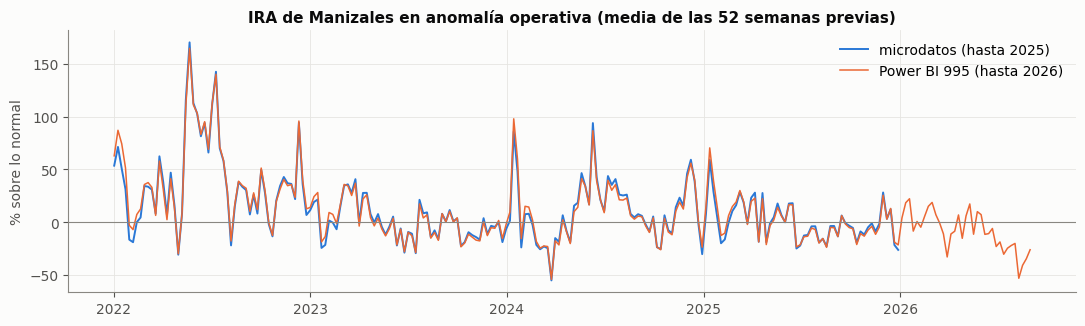

In [15]:
pbi = RAIZ / "calendarios/vigilancia/powerbi/2026-09-28"
tab = pd.read_csv(pbi / "ira_995_tablero.csv")
def inicio_se(anio, se):
    e4 = pd.Timestamp(anio, 1, 4); d1 = e4 - pd.Timedelta(days=(e4.dayofweek + 1) % 7)    # domingo de la SE1
    return d1 + pd.Timedelta(weeks=int(se) - 1)
tab["fecha"] = [inicio_se(a, s) for a, s in zip(tab.anio, tab.semana)]
ira_pbi = tab.groupby("fecha")["grup_total"].sum().sort_index()
ultima = ira_pbi.index.max()
ira_pbi_firme = ira_pbi.loc[:ultima - pd.Timedelta(weeks=2)]           # las 2 ultimas se corrigen con la notificacion tardia
micro = S[("manizales", "IRA total")]
sol = pd.concat([micro.rename("micro"), ira_pbi.rename("pbi")], axis=1).dropna().loc["2021":"2025"]
print(f"Power BI 995: {ira_pbi.index.min().date()} a {ultima.date()} ({len(ira_pbi)} semanas); se usan hasta {ira_pbi_firme.index.max().date()}")
print("Nivel Power BI / microdatos por año:", (sol.groupby(sol.index.year).sum().pipe(lambda d: d.pbi / d.micro)).round(3).to_dict())
print(f"r semanal en log, 2021-2025: {np.log(sol.micro).corr(np.log(sol.pbi)):.3f}")

rej2 = pd.date_range("2015-01-04", ira_pbi_firme.index.max(), freq="W-SUN")
t2 = rej2.dayofyear.values / 365.25
F2 = pd.DataFrame({f"{n}{k}": f(2 * np.pi * k * t2) for k in (1, 2, 3) for n, f in (("s", np.sin), ("c", np.cos))}, index=rej2); F2.insert(0, "c", 1.0)
def anomalia_operativa(s, ventana=52):
    """Operativa: estación típica ajustada hasta 2024 y nivel = media móvil de las 52 semanas previas (sin mirar el futuro)."""
    l = np.log1p(s.astype(float).reindex(rej2))
    ok = l.notna().values & (~rej2.to_series().between(*COVID)).values & (rej2 <= "2024-12-31")
    lc = l - l.groupby(l.index.year).transform("mean")
    b, *_ = np.linalg.lstsq(F2.values[ok], lc.values[ok], rcond=None)
    r = l - F2.values @ b
    return r - r.shift(1).rolling(ventana, min_periods=40).mean()
op_pbi = anomalia_operativa(ira_pbi_firme)
op_micro = anomalia_operativa(micro)
print(f"Anomalía operativa, Power BI vs microdatos, 2022-2025: r = {op_pbi.loc['2022':'2025'].corr(op_micro.loc['2022':'2025']):.3f}")
print(f"Anomalía operativa vs anomalía del cuaderno (con la media del año), microdatos 2022-2025: r = "
      f"{op_micro.loc['2022':'2025'].corr(A[('manizales', 'IRA total')].reindex(rej2).loc['2022':'2025']):.3f}")
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(op_micro.loc["2022":].index, 100 * (np.exp(op_micro.loc["2022":]) - 1), color=AZUL, lw=1.4, label="microdatos (hasta 2025)")
ax.plot(op_pbi.loc["2022":].index, 100 * (np.exp(op_pbi.loc["2022":]) - 1), color=NARANJA, lw=1.1, label="Power BI 995 (hasta 2026)")
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("% sobre lo normal"); ax.legend()
ax.set_title("IRA de Manizales en anomalía operativa (media de las 52 semanas previas)"); plt.show()

## Lectura

**La IRA de la ciudad sí se puede calcular a tiempo con Power BI, y da lo mismo que los microdatos.**
- El tablero 995 cubre de 2015-01 a 2026-09-13; se descartan las 2 últimas semanas por notificación tardía y se usa hasta el 2026-08-30.
- Va un **4-8 % por encima** de los microdatos todos los años (1,040 a 1,079), como ya decía `VIGILANCIA.md`. Es un nivel, y la anomalía lo quita.
- La **anomalía operativa** (estación típica hasta 2024 y nivel = media de las 52 semanas previas, sin mirar el futuro) calculada con Power BI correlaciona **0,989** con la misma calculada con microdatos.
- Contra la anomalía de este cuaderno (media del año entero) correlaciona **0,806**: cambiar a la versión operativa **no es gratis**. Cualquier resultado de este cuaderno habría que medirlo otra vez con la anomalía operativa antes de usarlo para pronosticar.
- En 2026 la IRA de la ciudad va, casi todo el año, **por debajo** de lo normal (figura).

**Qué se puede calcular a tiempo y qué no:**

| Serie | ¿A tiempo? | Cómo |
|---|---|---|
| IRA de Manizales por edad (el grueso de PC1) | **Sí**, con 2-3 semanas de margen | Power BI 995, congelado cada semana |
| IRAG hospitalización y UCI de Manizales | Sí, en total | Power BI 006 (`ira_995_rutinaria`) |
| Eventos individuales de Manizales | Sí | Power BI 006 y tableros por evento |
| EDA 998 de Manizales (y con ella PC2) | **No todavía**: el tablero existe, no se ha descargado | Hay que validar el filtro de municipio |
| Caldas sin Manizales, Colombia | **No con lo congelado** (solo Manizales) | El tablero 995 trae el municipio de cada institución: se podría pedir |
| Cualquier cosa con microdatos | **No**: ~8 meses de retraso | Solo para descubrir y medir |

**Límite.** Hay una sola instantánea (28-09-2026). Las semanas recientes se reescriben con la notificación tardía, y sin una instantánea por semana no se sabe qué valor se conocía en cada fecha. Una evaluación honesta de pronóstico necesita esa serie de instantáneas.

---
# 7. Qué entra al repertorio y qué no

**Resumen de la vigilancia completa:**

| Paso | Pruebas | Sobreviven a BH (rezago ≥ 1) | Confirmadas en 2025 | Resisten estación y rezagos negativos |
|---|---|---|---|---|
| Barrido, 59 series de Manizales y Caldas | 531 | 10 (5 series) | 3 (1 serie: EDA hospitalizados de Caldas, 4-6 semanas) | **0** |
| Componentes de presión epidemiológica × 4 desenlaces | 144 | 8 | 1 (PC3 → respiratorio, 5 semanas) | **0** (resiste la estación, pero sin mecanismo y con 0,4 esperadas por azar) |
| Geografías contra el triage (exploratorio) | 48 | 0 | — | — |

**Entra al repertorio: nada de la vigilancia, como predictor del triage total.** La salud de la ciudad no mueve el total del hospital de forma que se pueda distinguir del calendario y de la estación. Es coherente con lo que se esperaba del tamaño: la ola respiratoria de la ciudad va con +11 a +14 % en el respiratorio del hospital y con menos de +2 % en el total. **Se diluye.**

**Queda como candidato, sin entrar, una sola cosa: el índice respiratorio de la ciudad (PC1, dominado por la IRA de Manizales por edad) para el desenlace respiratorio del hospital.**
- Tiene mecanismo (contagio comunitario → consulta), el mismo tamaño en los dos periodos (+8,7 % y +10,6 % por desviación típica a 1 semana) y se calcula a tiempo con Power BI.
- **No pasó el criterio** (p = 0,055 en 2025). No se da por confirmado ni se ajusta nada para que pase.
- Su adelanto natural sería la IRA del **resto de Caldas**, que va una semana antes (p = 0,009), pero hoy no se congela.
- Condición para que entre: confirmarlo en 2026 con instantáneas semanales de Power BI y la anomalía operativa, con la prueba de estación y la de rezagos negativos.

**Queda de contexto, sin entrar:**
- EDA hospitalizada: acompaña a la estación, no la anticipa.
- PC2 (gastro), PC3 (salud mental), PC4 (violencia): los dos últimos, además, inestables.
- Precedencia de Caldas sobre Manizales: útil para la IRA de la ciudad, no para el hospital.
- EDA de Colombia a 7 semanas: signo constante, no pasa la corrección, sin mecanismo.
- Los eventos individuales con fuga (suicidio, violencias, intoxicaciones, agresiones, materna): **son desenlaces, no predictores**. Si se usan, como el respiratorio: series específicas del hospital para entender qué parte del total se mueve.

**Tres cosas que este cuaderno deja para el resto del proyecto:**
1. **La prueba de estación y la de rezagos negativos pasan a ser obligatorias** antes de dar un resultado por confirmado. Sin ellas, aquí habrían entrado dos predictores falsos.
2. **Un error en la fuente**: la SE53 de 2025 del 998 multiplica por ~7 la EDA de Manizales. Hay que corregirlo en `calendarios/vigilancia/sivigila.py`.
3. **Congelar Power BI cada semana.** Sin eso, ninguna serie de vigilancia se puede evaluar como pronóstico.

**Límites de todo el cuaderno.**
- Confirmar con 52 semanas tiene poca potencia: un efecto real de ~1,5 % por desviación típica puede no confirmarse.
- La anomalía usa la media del año entero, que en operación no existe (sección 6).
- El desenlace conserva la estacionalidad a propósito. Eso hace que una serie con estación mal quitada parezca predictora: es justo lo que pasó con la EDA hospitalizada.